# Brazil influenza: Mechanistic SEIR → Standard PINN → Bayesian uncertainty → Probabilistic forecasting

**Framework**

$$\text{Brazil data}\rightarrow\text{Mechanistic SEIR}\rightarrow\text{Standard PINN}\rightarrow\text{Bayesian uncertainty}\rightarrow\text{Out-of-sample forecasting}$$

| Stage | What is done | Uses test weeks 55–72? |
|---|---|---|
| 1 | Mechanistic SEIR calibrated on weeks 1–54, extrapolated to weeks 55–72 | No |
| 2 | Standard PINN (SEIR physics + I(t) data), forecast weeks 55–72 | No (physics-only collocation points in the forecast window, no observations) |
| 3 | Bayesian posterior $p(\theta\mid D_{train})$ by MCMC, then $p(R_0\mid D)$ | No |
| 4 | Posterior-predictive forecast (95% PI) for weeks 55–72, from both the ODE and the PINN ensemble | Only for scoring |
| 5 | Comparative and ablation studies (framework comparison, physics-weight ablation, rolling origin, robustness) | Only for scoring |

**Two honest caveats built into this notebook**

1. *The surveillance series is not the latent compartment $I(t)$.* Following the manuscript, $Y_t$ is compared directly with $I(t)$ (reporting scale $\rho=1$). The Bayesian stage adds a Negative-Binomial observation model on top of this convention.
2. *Initial-condition diagnostic.* With the Table-1 fixed constants and $E(0)=I(0)=Y_1$, the 3-parameter model could not fit these data in testing (see Block 5 gate). This notebook therefore treats the unobserved initial exposed count $E(0)$ as a 4th calibrated quantity and widens the bounds. Set `ESTIMATE_E0 = False` to reproduce the strict 3-parameter protocol.

## Block 1 — Configuration

In [ ]:
import os, time, warnings
warnings.filterwarnings("ignore")

FAST_TEST = False      # True = tiny run to check that the notebook executes (results NOT meaningful)

# ---- data / split
DATA_FILE   = "influenza.csv"
TRAIN_FRAC  = 0.75                 # 54 train / 18 test for N = 72

# ---- model assumptions
N0           = 6_000.0             # population scale. ASSUMPTION: 6,000 is the value implied by the manuscript's R0 = 1.6034 (Table 1 + Eq. 5.1); 10,000 is NOT consistent with it
ESTIMATE_E0  = True                # estimate the unobserved initial exposed count E(0)
N_STARTS = 15 if FAST_TEST else 300   # random starts for Stage-1 least squares (landscape is rugged: only ~1% of starts reach the best basin)

# ---- Bayesian stage
N_CHAINS     = 2 if FAST_TEST else 4
N_ITER       = 600 if FAST_TEST else 8000   # per chain
N_BURN       = 300 if FAST_TEST else 3000
N_POST_DRAWS = 100 if FAST_TEST else 1000   # posterior draws kept for prediction

# ---- PINN stage
PINN_EPOCHS      = 300 if FAST_TEST else 6000
N_COLLOC         = 200 if FAST_TEST else 400
PHYSICS_IN_FORECAST_WINDOW = True  # physics-only collocation points beyond week 54 (NO test observations used)
W_DATA, W_PHYS, W_IC = 100.0, 1.0, 10.0

# ---- Bayesian-PINN ensemble (posterior-propagated PINNs)
RUN_PINN_ENSEMBLE = True
K_ENSEMBLE        = 3 if FAST_TEST else 20
FT_EPOCHS         = 100 if FAST_TEST else 1500

# ---- comparative / ablation studies (Blocks 13-18)
RUN_STUDIES    = True
STUDY_STARTS   = 8 if FAST_TEST else 40       # random starts per calibration inside the studies (lighter than Stage 1)
STUDY_CHAINS   = 2
STUDY_ITER     = 500 if FAST_TEST else 2500   # MCMC iterations per chain inside the studies
STUDY_BURN     = 250 if FAST_TEST else 1000
STUDY_DRAWS    = 100 if FAST_TEST else 600
RO_ORIGINS     = [30, 42] if FAST_TEST else [30, 36, 42, 48, 54, 60]   # rolling-origin: number of training weeks
RO_H           = 12                           # forecast horizon (weeks) at every origin
ROBUST_SPLITS  = [43] if FAST_TEST else [43, 61]    # 60/40 and 85/15 chronological splits
PHYS_W_LIST    = [0.0, 0.1, 1.0, 10.0]        # PINN physics-weight ablation (0 = data-only network)

SEED = 42
FIG_DIR = "figures_brazil_full"
os.makedirs(FIG_DIR, exist_ok=True)

## Block 2 — Imports

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.special import gammaln

try:
    import torch, torch.nn as nn, torch.optim as optim
    HAVE_TORCH = True
except Exception as e:
    HAVE_TORCH = False
    print("PyTorch not available -> PINN stages will be skipped:", e)

rng_global = np.random.default_rng(SEED)
np.random.seed(SEED)
if HAVE_TORCH:
    torch.manual_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    dtype = torch.float32
    print("device:", device)

# Bold text everywhere (axis labels, tick labels, legends, titles, annotations). Set BOLD_ALL_FIGURES = False to disable.
BOLD_ALL_FIGURES = True
plt.rcParams.update({"mathtext.fontset": "stix", "font.family": "DejaVu Sans", "figure.dpi": 110,
                     "axes.labelweight": "bold", "axes.titleweight": "bold", "axes.labelsize": 11, "legend.fontsize": 9})
if BOLD_ALL_FIGURES:
    plt.rcParams.update({"font.weight": "bold", "figure.titleweight": "bold", "axes.linewidth": 1.2,
                         "xtick.major.width": 1.2, "ytick.major.width": 1.2})
def savefig(name):
    """Save PNG (used by the .tex) and a vector PDF copy, then show inline."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=300, bbox_inches="tight")
    plt.savefig(os.path.join(FIG_DIR, name.rsplit(".", 1)[0] + ".pdf"), bbox_inches="tight")
    plt.show()

COLORS = {"Mechanistic SEIR": "C0", "Standard PINN": "C3",
          "Bayesian SEIR (posterior median)": "C1", "Bayesian-uncertainty PINN ensemble": "C2"}

FORECASTS = {}   # model name -> dict(point=array(72), lo=array(72)|None, hi=array(72)|None)

device: cpu


## Block 3 — Data and chronological split (Figure 1)

N=72  train=54 (2012-W43..2013-W44)  test=18 (2013-W45..2014-W10)


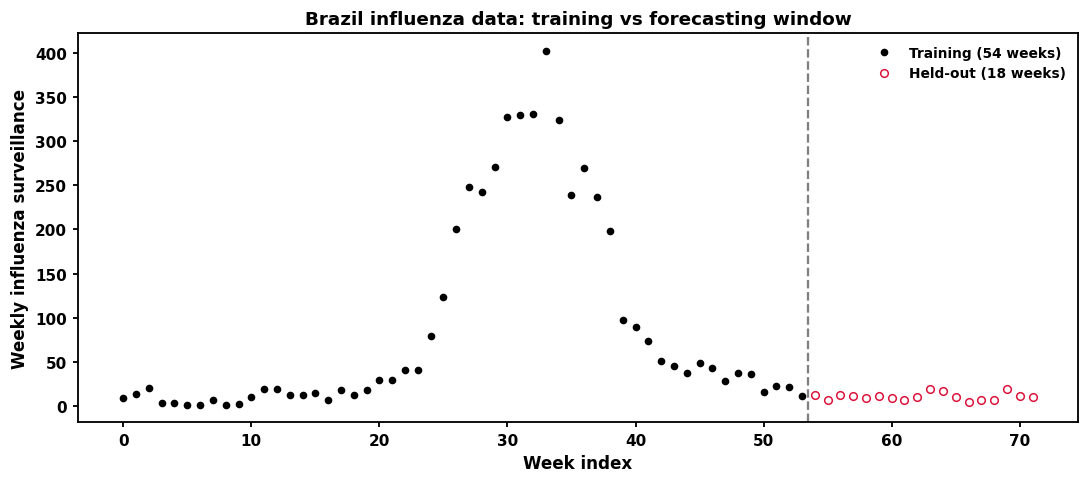

In [ ]:
df = pd.read_csv(DATA_FILE)
df.columns = [c.strip() for c in df.columns]
df["Surveillance"] = pd.to_numeric(df["Surveillance"], errors="raise")
y = df["Surveillance"].to_numpy(float)
N = len(y)
N_TRAIN = int(np.floor(TRAIN_FRAC * N)); N_TEST = N - N_TRAIN
t_all = np.arange(N, dtype=float)
t_train, t_test = t_all[:N_TRAIN], t_all[N_TRAIN:]
y_train, y_test = y[:N_TRAIN], y[N_TRAIN:]
print(f"N={N}  train={N_TRAIN} ({df['Week'].iloc[0]}..{df['Week'].iloc[N_TRAIN-1]})  "
      f"test={N_TEST} ({df['Week'].iloc[N_TRAIN]}..{df['Week'].iloc[-1]})")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(t_train, y_train, "ko", ms=4, label="Training (54 weeks)")
ax.plot(t_test, y_test, "o", mfc="none", mec="crimson", ms=5, label="Held-out (18 weeks)")
ax.axvline(N_TRAIN - 0.5, ls="--", c="gray")
ax.set_xlabel("Week index"); ax.set_ylabel("Weekly influenza surveillance")
ax.set_title("Brazil influenza data: training vs forecasting window"); ax.legend(frameon=False)
savefig("fig01_data_split.png")

## Block 4 — Nonlinear SEIR model (manuscript Eq. 2.7) and fixed parameters

In [ ]:
mu = 1.0 / (74.6 * 52.0)
FIXED = dict(N0=N0, Lambda=mu * N0, beta1=1e-6, beta3=1e-8, k=30.0, mu=mu,
             delta=0.007, gamma=0.002, eta=0.1, omega=0.07)

def seir_rhs(t, X, p):
    S, E, I, R = X
    lam   = p["beta1"] * E + (p["beta2"] - p["beta3"] * I / (p["k"] + I)) * I
    treat = p["tau"] * I / (1.0 + p["eta"] * I)
    return [p["Lambda"] - lam * S - p["mu"] * S + p["omega"] * R,
            lam * S - (p["sigma"] + p["mu"]) * E,
            p["sigma"] * E - (p["mu"] + p["delta"] + p["gamma"]) * I - treat,
            p["gamma"] * I + treat - (p["mu"] + p["omega"]) * R]

def initial_state(E0):
    I0 = max(float(y_train[0]), 1.0)          # I(0) = first training observation
    return np.array([N0 - E0 - I0, E0, I0, 0.0])   # R(0) = 0

def simulate(beta2, sigma, tau, E0, t_eval, full=False):
    """Return I(t) (or the full 4-state trajectory); NaN array if the solver fails."""
    p = {**FIXED, "beta2": beta2, "sigma": sigma, "tau": tau}
    try:
        sol = solve_ivp(lambda t, X: seir_rhs(t, X, p), (0.0, float(t_eval[-1])), initial_state(E0),
                        t_eval=t_eval, method="LSODA", rtol=1e-7, atol=1e-9)
        if (not sol.success) or sol.y.shape[1] != len(t_eval) or not np.all(np.isfinite(sol.y)):
            raise RuntimeError
        return sol.y.T if full else sol.y[2]
    except Exception:
        return np.full((len(t_eval), 4) if full else len(t_eval), np.nan)

def R0_fn(beta2, sigma, tau):
    return N0 * (FIXED["beta1"] / (sigma + mu)
                 + beta2 * sigma / ((sigma + mu) * (mu + FIXED["delta"] + FIXED["gamma"] + tau)))

def metrics(y_true, y_pred):
    e = y_pred - y_true
    return {"RMSE": float(np.sqrt(np.mean(e**2))), "MAE": float(np.mean(np.abs(e))),
            "sMAPE_%": float(100*np.mean(2*np.abs(e)/(np.abs(y_true)+np.abs(y_pred)+1e-8)))}

## Block 5 — Stage 1: mechanistic calibration on weeks 1–54 only

Many-start bounded least squares in log-parameter space, followed by a tight polish of the best fit. Starts are random inside the bounds — **the full-data values from the manuscript are deliberately not used**, so nothing from weeks 55–72 leaks in.

Bounds are wide and data-independent. They are also used later as the (log-uniform) Bayesian priors.

In [ ]:
PNAMES = ["beta2", "sigma", "tau"] + (["E0"] if ESTIMATE_E0 else [])
LOW  = np.array([1e-6, 1e-2, 1e-3, 1e-2][:len(PNAMES)])
HIGH = np.array([1e-2, 2.0,  50.0, 3e3 ][:len(PNAMES)])
LLOW, LHIGH = np.log(LOW), np.log(HIGH)
SCALE = max(np.std(y_train), 1.0)

def split_theta(th):
    th = np.asarray(th, float)
    return th[0], th[1], th[2], (th[3] if ESTIMATE_E0 else float(y_train[0]))

def resid(z):
    pred = simulate(*split_theta(np.exp(z)), t_train)
    return np.full(N_TRAIN, 1e3) if np.any(np.isnan(pred)) else (pred - y_train) / SCALE

t0 = time.time(); rng = np.random.default_rng(SEED)
# The SEIR least-squares landscape is rugged (peak timing depends exponentially on E(0), beta2): in testing only
# ~1% of random starts reached the best basin. Hence many cheap random starts, then a tight polish of the winner.
fits = []
for i in range(N_STARTS):
    try:
        r = least_squares(resid, rng.uniform(LLOW, LHIGH), bounds=(LLOW, LHIGH), method="trf", max_nfev=150)
        fits.append(r)
    except Exception:
        pass
fits.sort(key=lambda r: r.cost)
best = least_squares(resid, fits[0].x, bounds=(LLOW, LHIGH), method="trf", max_nfev=800, xtol=1e-12, ftol=1e-12, gtol=1e-12)
n_good = sum(r.cost < 1.05 * fits[0].cost for r in fits)
print(f"{n_good}/{len(fits)} starts reached the best basin (cost within 5% of best)")
print(f"Stage-1 calibration done in {time.time()-t0:.0f}s, best cost = {best.cost:.4f}")

THETA_MECH = np.exp(best.x)
b2_m, s_m, tau_m, E0_m = split_theta(THETA_MECH)
X_mech_all = simulate(b2_m, s_m, tau_m, E0_m, t_all, full=True)
y_mech_all = X_mech_all[:, 2]

calib = pd.DataFrame({"estimate": THETA_MECH, "lower_bound": LOW, "upper_bound": HIGH}, index=PNAMES)
calib["at_bound"] = (np.abs(best.x - LLOW) < 0.01*(LHIGH-LLOW)) | (np.abs(best.x - LHIGH) < 0.01*(LHIGH-LLOW))
display(calib) if "display" in globals() else print(calib)

# ---- diagnostic gate: is the mechanistic model better than predicting the training mean?
m_tr = metrics(y_train, y_mech_all[:N_TRAIN])
print(f"\nSEIR train RMSE = {m_tr['RMSE']:.2f}   |   constant-mean baseline train RMSE = {np.std(y_train):.2f}")
if m_tr["RMSE"] > 0.7 * np.std(y_train) or calib["at_bound"].any():
    print("\n*** WARNING: the mechanistic fit is poor and/or parameters sit on their bounds. ***\n"
          "    Check ESTIMATE_E0, N0 and the fixed constants BEFORE interpreting PINN/Bayesian results.")
else:
    print("Gate passed: mechanistic model clearly beats the constant-mean baseline on the training weeks.")
FORECASTS["Mechanistic SEIR"] = dict(point=y_mech_all, lo=None, hi=None)

14/300 starts reached the best basin (cost within 5% of best)
Stage-1 calibration done in 408s, best cost = 0.8317
         estimate  lower_bound  upper_bound  at_bound
beta2    0.006889     0.000001         0.01     False
sigma    0.095156     0.010000         2.00     False
tau     28.658517     0.001000        50.00     False
E0     551.072739     0.010000      3000.00     False

SEIR train RMSE = 19.75   |   constant-mean baseline train RMSE = 112.55
Gate passed: mechanistic model clearly beats the constant-mean baseline on the training weeks.


## Block 6 — Mechanistic baseline: Figures 2–4, error table and $R_0$

                        RMSE     MAE  sMAPE_%
SEIR train            19.753  12.843   38.354
SEIR test              4.502   3.282   29.791
mean-baseline train  112.548  92.372  111.589
mean-baseline test    78.737  78.630  156.678


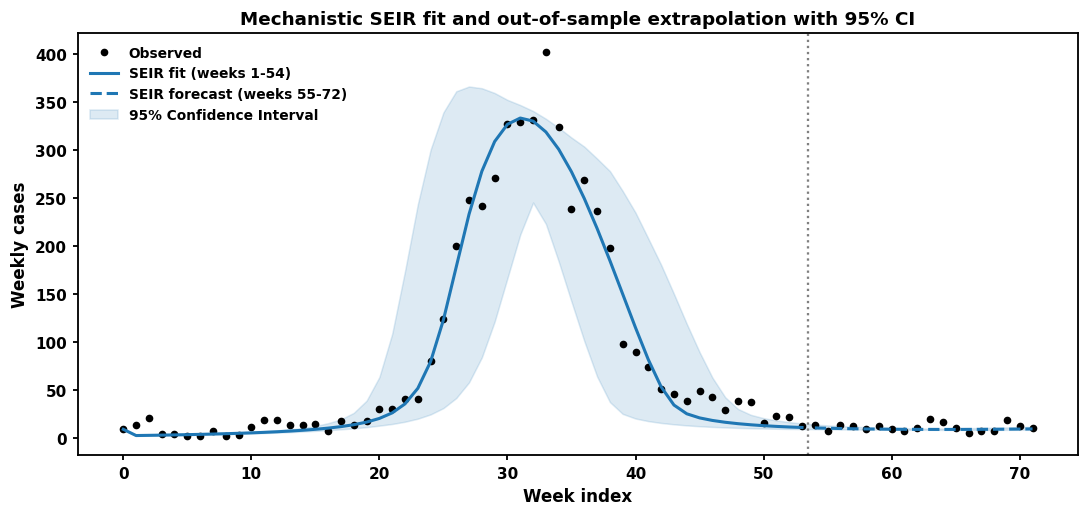

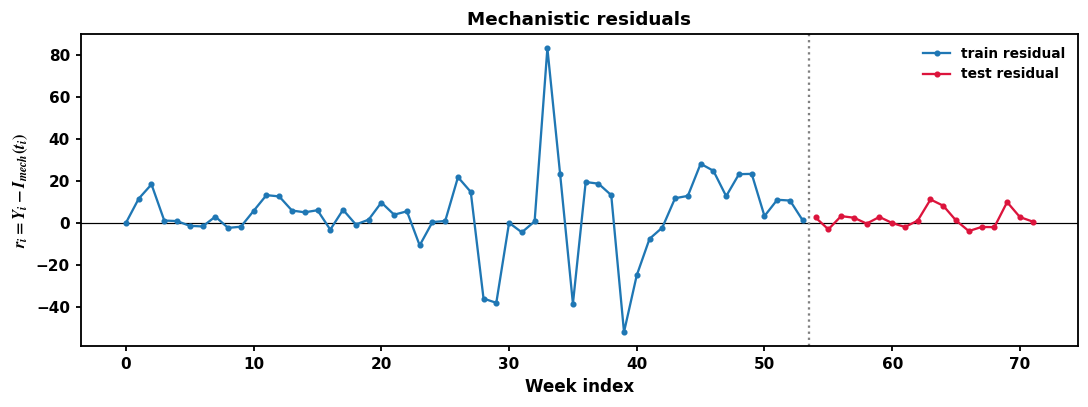

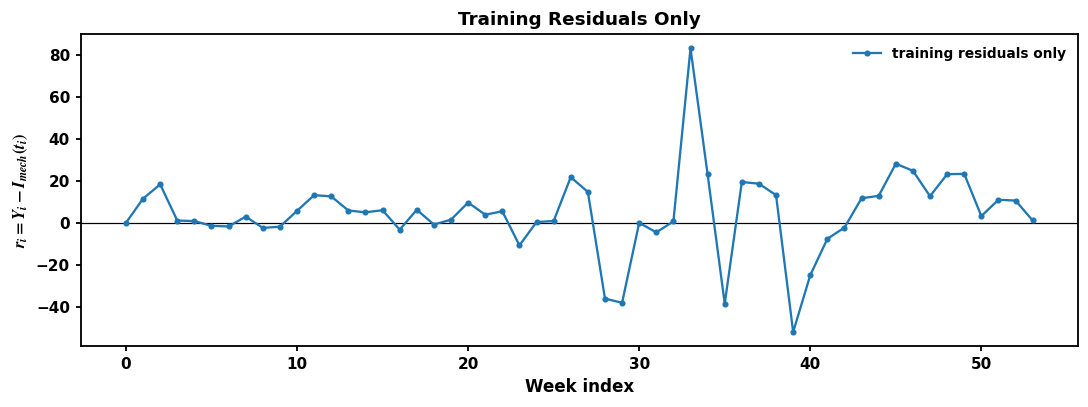


Training-only R0 (point estimate) = 1.5007


In [ ]:
def metrics(y_true, y_pred):
    e = y_pred - y_true
    return {"RMSE": float(np.sqrt(np.mean(e**2))), "MAE": float(np.mean(np.abs(e))),
            "sMAPE_%": float(100*np.mean(2*np.abs(e)/(np.abs(y_true)+np.abs(y_pred)+1e-8)))}

m_tr = metrics(y_train, y_mech_all[:N_TRAIN])
m_te = metrics(y_test, y_mech_all[N_TRAIN:])
base_tr = metrics(y_train, np.full(N_TRAIN, y_train.mean())); base_te = metrics(y_test, np.full(N_TEST, y_train.mean()))
print(pd.DataFrame({"SEIR train": m_tr, "SEIR test": m_te, "mean-baseline train": base_tr, "mean-baseline test": base_te}).T.round(3))

# Calculate confidence intervals via asymptotic covariance (delta-method / Jacobian)
dof = max(N_TRAIN - len(PNAMES), 1)
s2 = 2.0 * best.cost / dof
cov = s2 * np.linalg.pinv(best.jac.T @ best.jac)

# Sample parameters in log-space to propagate uncertainty
r_uq = np.random.default_rng(SEED)
z_samples = r_uq.multivariate_normal(best.x, cov, size=200)
curve_samples = []
for zs in z_samples:
    pred_s = simulate(*split_theta(np.exp(zs)), t_all)
    if not np.any(np.isnan(pred_s)):
        curve_samples.append(pred_s)
curve_samples = np.array(curve_samples)
ci_lo, ci_hi = np.percentile(curve_samples, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(t_all, y, "ko", ms=4, label="Observed")
ax.plot(t_train, y_mech_all[:N_TRAIN], lw=2, c="C0", label="SEIR fit (weeks 1-54)")
ax.plot(t_test, y_mech_all[N_TRAIN:], lw=2, ls="--", c="C0", label="SEIR forecast (weeks 55-72)")
ax.fill_between(t_all, ci_lo, ci_hi, color="C0", alpha=0.15, label="95% Confidence Interval")
ax.axvline(N_TRAIN-0.5, ls=":", c="gray"); ax.set_xlabel("Week index"); ax.set_ylabel("Weekly cases")
ax.set_title("Mechanistic SEIR fit and out-of-sample extrapolation with 95% CI"); ax.legend(frameon=False)
savefig("fig02_mech_fit_forecast.png")

res_all = y - y_mech_all
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axhline(0, c="k", lw=.8); ax.axvline(N_TRAIN-0.5, ls=":", c="gray")
ax.plot(t_train, res_all[:N_TRAIN], "o-", ms=3, label="train residual")
ax.plot(t_test, res_all[N_TRAIN:], "o-", ms=3, c="crimson", label="test residual")
ax.set_xlabel("Week index"); ax.set_ylabel(r"$r_i = Y_i - I_{mech}(t_i)$"); ax.legend(frameon=False)
ax.set_title("Mechanistic residuals"); savefig("fig04_mech_residuals.png")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axhline(0, c="k", lw=.8)
ax.plot(t_train, res_all[:N_TRAIN], "o-", ms=3, c="C0", label="training residuals only")
ax.set_xlabel("Week index"); ax.set_ylabel(r"$r_i = Y_i - I_{mech}(t_i)$"); ax.legend(frameon=False)
ax.set_title("Training Residuals Only"); savefig("fig04b_train_residuals.png")

print(f"\nTraining-only R0 (point estimate) = {R0_fn(b2_m, s_m, tau_m):.4f}")

## Block 6b — Plotting helpers (full series + zoom on the forecast window)

In [ ]:
def forecast_figure(curves, bands, fname, title, zoom=True):
    """curves: [(label, array(72), colour, linestyle)];  bands: [(lo, hi, colour, alpha, label)].
    Left panel = full series. Right panel = zoom on the forecast window, because the held-out counts are
    small relative to the epidemic peak and would otherwise be unreadable at paper width."""
    if zoom:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
    else:
        fig, ax0 = plt.subplots(figsize=(9, 4.6)); axes = [ax0]
    z0 = max(0, N_TRAIN - 6)
    for k, ax in enumerate(axes):
        for lo, hi, c, a, lab in bands:
            ax.fill_between(t_all, lo, hi, color=c, alpha=a, lw=0, label=lab if k == 0 else None)
        for lab, arr, c, ls in curves:
            ax.plot(t_all, arr, c=c, ls=ls, lw=2, label=lab if k == 0 else None)
        ax.plot(t_train, y_train, "ko", ms=3.5, label="Training data" if k == 0 else None)
        ax.plot(t_test, y_test, "o", mfc="white", mec="crimson", ms=4.5, mew=1.3,
                label="Held-out data" if k == 0 else None)
        ax.axvline(N_TRAIN - 0.5, ls=":", c="gray"); ax.set_xlabel("Week index")
    axes[0].set_ylabel("Weekly cases")
    axes[0].legend(frameon=False, ncol=2, loc="upper left")
    if zoom:
        win = slice(z0, N)
        top = max([np.nanmax(y[win])] + [np.nanmax(a[win]) for _, a, _, _ in curves]
                  + [np.nanmax(b[1][win]) for b in bands])
        axes[1].set_xlim(z0 - 0.5, N - 0.5); axes[1].set_ylim(0, 1.15 * top)
        axes[0].set_title("Full series"); axes[1].set_title("Forecast window (zoom)")
        fig.suptitle(title, fontweight="bold")
    else:
        axes[0].set_title(title)
    savefig(fname)

def plot_pinn_vs_mech(y_pinn):
    """fig_pinn_vs_mech.png : standard PINN vs mechanistic SEIR (Stage-2 section of the paper)."""
    forecast_figure([("Mechanistic SEIR", y_mech_all, COLORS["Mechanistic SEIR"], "--"),
                     ("Standard PINN", y_pinn, COLORS["Standard PINN"], "-")], [],
                    "fig_pinn_vs_mech.png", "Standard PINN vs mechanistic SEIR")

## Block 7 — Stage 2: standard PINN

* Network $t\mapsto(\hat S,\hat E,\hat I,\hat R)$: 1 → 32 → 32 → 4 (tanh), softplus outputs for positivity.
* ODE parameters $\hat\theta_{mech}$ and initial state are **fixed** at the Stage-1 values.
* Data loss: only $I$ is observed, weeks 1–54 only.
* Physics loss: SEIR residuals at collocation points. With `PHYSICS_IN_FORECAST_WINDOW=True` collocation points also lie in weeks 55–72. These carry **no observations** — they only enforce the equations, which is what lets the PINN extrapolate meaningfully.

epoch     1 | total 9.875e+01 | data 5.242e-01 | phys 4.434e+01 | IC 1.980e-01
epoch  1000 | total 1.857e-01 | data 1.763e-03 | phys 9.145e-03 | IC 2.415e-05
epoch  2000 | total 1.712e-01 | data 1.636e-03 | phys 7.557e-03 | IC 7.390e-06
epoch  3000 | total 1.477e-01 | data 1.434e-03 | phys 4.274e-03 | IC 5.065e-06
epoch  4000 | total 1.266e-01 | data 1.247e-03 | phys 1.881e-03 | IC 7.142e-06
epoch  5000 | total 1.172e-01 | data 1.158e-03 | phys 1.332e-03 | IC 7.445e-06
epoch  6000 | total 1.136e-01 | data 1.122e-03 | phys 1.288e-03 | IC 7.526e-06


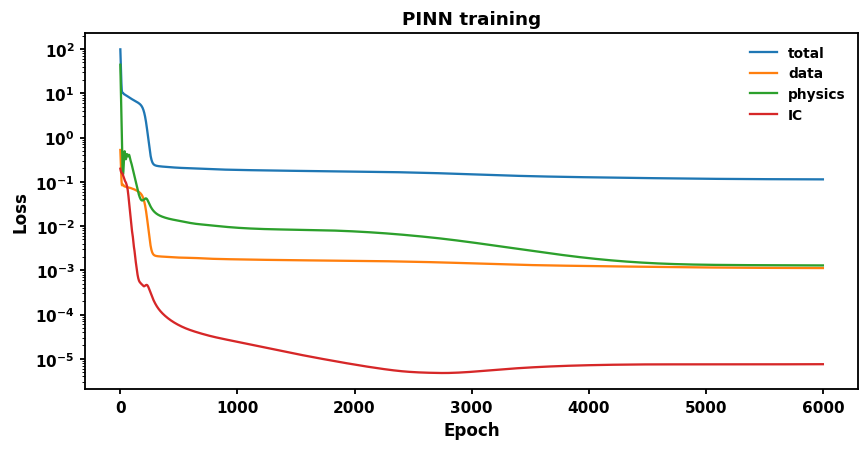

PINN train: {'RMSE': 13.465318861481258, 'MAE': 8.906464046902126, 'sMAPE_%': 27.562131136475465}
PINN test : {'RMSE': 4.843255099081578, 'MAE': 3.4977160029941134, 'sMAPE_%': 31.281638155395697}


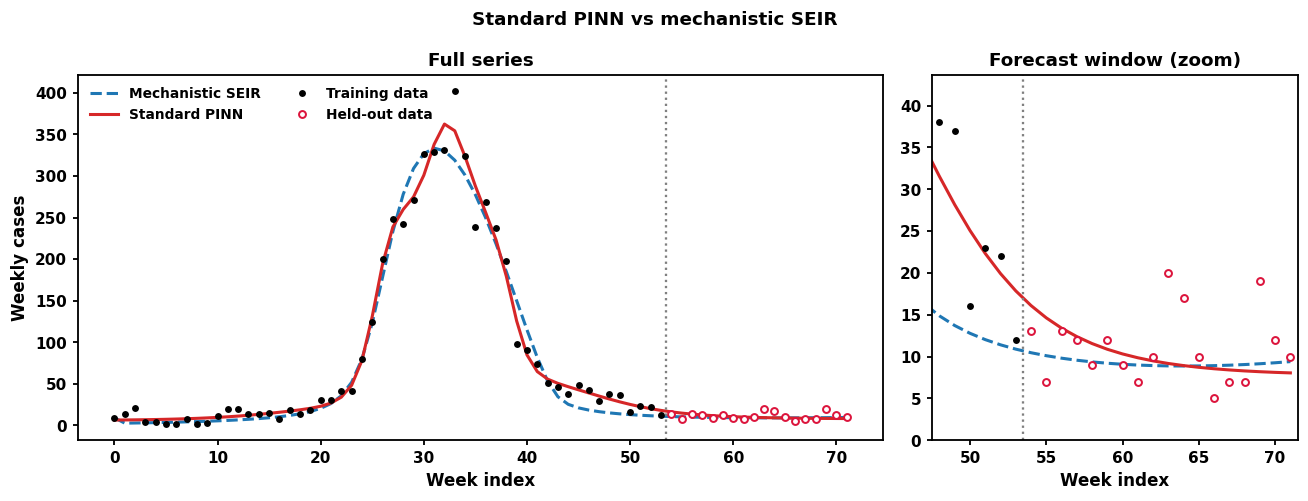

In [ ]:
if HAVE_TORCH:
    T_SCALE = float(t_all[-1])
    C_VEC = torch.tensor([[1.0, 0.1, 0.1, 0.5]], dtype=dtype, device=device)   # state scales (U = X/N0)
    Y_REF = float(np.max(y_train))

    class PINN(nn.Module):
        def __init__(self):
            super().__init__()
            self.net = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 4))
        def forward(self, t):
            return torch.nn.functional.softplus(self.net(t / T_SCALE)) * C_VEC     # U = X / N0

    def ode_rhs_scaled(U, p):
        X = p["N0"] * U
        S, E, I, R = X[:, 0:1], X[:, 1:2], X[:, 2:3], X[:, 3:4]
        lam   = p["beta1"] * E + (p["beta2"] - p["beta3"] * I / (p["k"] + I)) * I
        treat = p["tau"] * I / (1.0 + p["eta"] * I)
        dS = p["Lambda"] - lam * S - p["mu"] * S + p["omega"] * R
        dE = lam * S - (p["sigma"] + p["mu"]) * E
        dI = p["sigma"] * E - (p["mu"] + p["delta"] + p["gamma"]) * I - treat
        dR = p["gamma"] * I + treat - (p["mu"] + p["omega"]) * R
        return torch.cat([dS, dE, dI, dR], 1) / p["N0"]

    def d_dt(U, t):
        return torch.cat([torch.autograd.grad(U[:, i].sum(), t, create_graph=True)[0] for i in range(4)], 1)

    def to_torch_params(beta2, sigma, tau):
        d = {**FIXED, "beta2": beta2, "sigma": sigma, "tau": tau}
        return {k: torch.tensor(float(v), dtype=dtype, device=device) for k, v in d.items()}

    def train_pinn(model, p_t, U0_np, epochs, lr, t_col, verbose=True):
        t_obs = torch.tensor(t_train.reshape(-1, 1), dtype=dtype, device=device)
        y_obs = torch.tensor(y_train.reshape(-1, 1), dtype=dtype, device=device)
        U0 = torch.tensor(U0_np.reshape(1, -1) / N0, dtype=dtype, device=device)
        t0 = torch.zeros(1, 1, dtype=dtype, device=device)
        opt = optim.Adam(model.parameters(), lr=lr)
        sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=lr * 0.02)
        hist = []
        for ep in range(1, epochs + 1):
            opt.zero_grad()
            L_data = torch.mean(((N0 * model(t_obs)[:, 2:3] - y_obs) / Y_REF) ** 2)
            tc = t_col.clone().requires_grad_(True)
            Uc = model(tc)
            L_phys = torch.mean(((d_dt(Uc, tc) - ode_rhs_scaled(Uc, p_t)) / C_VEC) ** 2)
            L_ic = torch.mean(((model(t0) - U0) / C_VEC) ** 2)
            loss = W_DATA * L_data + W_PHYS * L_phys + W_IC * L_ic
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step(); sch.step()
            hist.append([loss.item(), L_data.item(), L_phys.item(), L_ic.item()])
            if verbose and (ep == 1 or ep % max(1, epochs // 6) == 0):
                print(f"epoch {ep:5d} | total {loss.item():.3e} | data {L_data.item():.3e} | phys {L_phys.item():.3e} | IC {L_ic.item():.3e}")
        return np.array(hist)

    @torch.no_grad()
    def pinn_I(model):
        model.eval()
        tt = torch.tensor(t_all.reshape(-1, 1), dtype=dtype, device=device)
        return (N0 * model(tt)[:, 2]).cpu().numpy()

    hi_t = t_all[-1] if PHYSICS_IN_FORECAST_WINDOW else t_train[-1]
    t_col = torch.tensor(np.sort(np.random.default_rng(SEED).uniform(0, hi_t, N_COLLOC)).reshape(-1, 1),
                         dtype=dtype, device=device)

    pinn = PINN().to(device)
    p_mech_t = to_torch_params(b2_m, s_m, tau_m)
    hist = train_pinn(pinn, p_mech_t, X_mech_all[0], PINN_EPOCHS, 2e-3, t_col)
    y_pinn_all = pinn_I(pinn)
    FORECASTS["Standard PINN"] = dict(point=y_pinn_all, lo=None, hi=None)

    fig, ax = plt.subplots(figsize=(8, 4.2))
    for j, lab in enumerate(["total", "data", "physics", "IC"]): ax.semilogy(hist[:, j], label=lab)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.set_title("PINN training"); ax.legend(frameon=False)
    savefig("fig05_pinn_training.png")
    print("PINN train:", metrics(y_train, y_pinn_all[:N_TRAIN]))
    print("PINN test :", metrics(y_test, y_pinn_all[N_TRAIN:]))
    plot_pinn_vs_mech(y_pinn_all)                       # -> fig_pinn_vs_mech.png
else:
    print("Skipped (no PyTorch).")

## Block 8 — Stage 3: Bayesian inference for $\theta=(\beta_2,\sigma,\tau[,E_0])$

**Likelihood** (training weeks only), with $\rho=1$ as in the manuscript:
$$Y_t\sim\mathrm{NegBin}\big(\text{mean}=I(t;\theta),\ \text{dispersion}=\phi\big),\qquad \mathrm{Var}=I+I^2/\phi .$$
**Priors:** log-uniform on the Block-5 bounds (data-independent); $\log\phi\sim U[\log 0.1,\log 10^3]$.
**Sampler:** adaptive random-walk Metropolis (Haario) on log-parameters, several chains, split-$\hat R$ and ESS reported.

In [ ]:
PHI_LOW, PHI_HIGH = 0.1, 1e3
BLOW  = np.append(LLOW,  np.log(PHI_LOW));  BHIGH = np.append(LHIGH, np.log(PHI_HIGH))
D = len(BLOW)

def nb_loglik(yv, m, phi):
    m = np.maximum(m, 1e-8)
    return np.sum(gammaln(yv + phi) - gammaln(phi) - gammaln(yv + 1.0)
                  + phi * (np.log(phi) - np.log(phi + m)) + yv * (np.log(m) - np.log(phi + m)))

def log_post(z):
    if np.any(z < BLOW) or np.any(z > BHIGH): return -np.inf
    th = np.exp(z)
    pred = simulate(*split_theta(th[:-1]), t_train)
    if np.any(np.isnan(pred)): return -np.inf
    return nb_loglik(y_train, pred, th[-1])          # log-uniform priors => flat in z inside the box

def run_chain(z0, n_iter, n_burn, seed):
    r = np.random.default_rng(seed)
    z, lp = z0.copy(), log_post(z0)
    cov = np.diag(((BHIGH - BLOW) * 0.01) ** 2); chain = np.empty((n_iter, D)); acc = 0
    for i in range(n_iter):
        if 500 <= i < n_burn and i % 250 == 0:                          # adapt during burn-in only
            c = np.cov(chain[max(0, i - 2000):i].T) + 1e-10 * np.eye(D)
            cov = (2.38 ** 2 / D) * c
        prop = r.multivariate_normal(z, cov)
        lpp = log_post(prop)
        if np.log(r.uniform()) < lpp - lp:
            z, lp = prop, lpp
            if i >= n_burn: acc += 1
        chain[i] = z
    return chain, acc / max(1, n_iter - n_burn)

def split_rhat(ch):                      # ch: (n_chains, n_draws)
    ch = np.concatenate([ch[:, :ch.shape[1]//2], ch[:, ch.shape[1]//2: 2*(ch.shape[1]//2)]], 0)
    n = ch.shape[1]; W = ch.var(1, ddof=1).mean(); B = n * ch.mean(1).var(ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)

def ess_1d(x):
    x = x - x.mean(); n = len(x); f = np.fft.rfft(x, 2 * n); ac = np.fft.irfft(f * np.conj(f))[:n]; ac /= ac[0]
    s = 0.0
    for k in range(1, n - 1, 2):
        pair = ac[k] + ac[k + 1]
        if pair < 0: break
        s += pair
    return n / (1 + 2 * s)

z_start = np.append(best.x, np.log(20.0))
chains, accs = [], []
t0 = time.time()
for c in range(N_CHAINS):
    z_init = np.clip(z_start + np.random.default_rng(100 + c).normal(0, 0.05, D), BLOW + 1e-3, BHIGH - 1e-3)
    ch, a = run_chain(z_init, N_ITER, N_BURN, seed=1000 + c); chains.append(ch); accs.append(a)
    print(f"chain {c+1}/{N_CHAINS} done ({time.time()-t0:.0f}s), post-burn acceptance = {a:.2f}")
chains = np.array(chains)[:, N_BURN:, :]                  # (C, n, D)
LABELS = PNAMES + ["phi"]
diag = pd.DataFrame({"split_Rhat": [split_rhat(chains[:, :, j]) for j in range(D)],
                     "ESS": [sum(ess_1d(chains[c, :, j]) for c in range(N_CHAINS)) for j in range(D)]}, index=LABELS)
print(diag.round(3));
if (diag["split_Rhat"] > 1.1).any():
    print("*** Some R-hat > 1.1: increase N_ITER/N_BURN before trusting the posterior. ***")

flat = np.exp(chains.reshape(-1, D))
idx = np.random.default_rng(SEED).choice(len(flat), size=min(N_POST_DRAWS, len(flat)), replace=False)
POST = flat[idx]                                          # posterior draws (theta..., phi)

chain 1/4 done (128s), post-burn acceptance = 0.45
chain 2/4 done (257s), post-burn acceptance = 0.27
chain 3/4 done (384s), post-burn acceptance = 0.25
chain 4/4 done (515s), post-burn acceptance = 0.23
       split_Rhat      ESS
beta2       1.006  865.384
sigma       1.006  673.296
tau         1.005  705.083
E0          1.006  935.092
phi         1.011  728.022


## Block 8a — Rank-normalised MCMC diagnostics
Section 7.1 of the manuscript cites rank-normalised split-$\hat R$ and ESS [41], but the sampler cell above computes the classical split-$\hat R$ and a summed per-chain ESS. This block adds the rank-normalised split-$\hat R$ (bulk and folded), bulk ESS and tail ESS (validated against ArviZ), acceptance and boundary proximity. The original columns are kept, so earlier numbers can be reproduced.

In [ ]:
# =====================================================================================================
# BLOCK 8a - rank-normalised MCMC diagnostics (Vehtari et al., 2021; the reference cited as [41] in the manuscript)
#   * split-Rhat on rank-normalised draws, taken as the maximum of the bulk and the folded (scale) version
#   * bulk ESS (rank-normalised draws) and tail ESS (5% / 95% quantile indicators), multi-chain, Geyer's initial positive sequence
#   * acceptance rate and parameter-wise boundary proximity
# Pure numpy/scipy: no ArviZ dependency. The original split_rhat()/ess_1d() above are kept, so earlier tables are reproducible.
# =====================================================================================================
from scipy.stats import rankdata, norm as _norm

def _split(ch):                               # (C, n) -> (2C, n//2)
    n = ch.shape[1] // 2
    return np.concatenate([ch[:, :n], ch[:, n:2 * n]], axis=0)

def _rhat_plain(ch):                          # ch: (M, n)
    M, n = ch.shape; W = ch.var(1, ddof=1).mean(); B = n * ch.mean(1).var(ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W) if W > 0 else np.nan

def _z_scale(x):                              # rank-normalise over all draws and chains
    r = rankdata(x.ravel(), method="average").reshape(x.shape)
    return _norm.ppf((r - 0.375) / (x.size + 0.25))

def rhat_rank(ch):
    """rank-normalised split-Rhat = max(bulk, folded). ch: (C, n)"""
    s = _split(np.asarray(ch, float))
    return float(max(_rhat_plain(_z_scale(s)), _rhat_plain(_z_scale(np.abs(s - np.median(s))))))

def _ess_core(x):
    """multi-chain ESS of x (M, n) following Vehtari et al. (2021); Geyer initial monotone positive sequence"""
    M, n = x.shape
    if n < 4 or np.allclose(x, x[0, 0]): return float("nan")
    xc = x - x.mean(1, keepdims=True); f = np.fft.rfft(xc, 2 * n, axis=1)
    acov = np.fft.irfft(f * np.conj(f), axis=1)[:, :n] / n
    mean_var = acov[:, 0].mean() * n / (n - 1.0)
    var_plus = mean_var * (n - 1.0) / n + (x.mean(1).var(ddof=1) if M > 1 else 0.0)
    if var_plus <= 0: return float("nan")
    rho = np.zeros(n); even = 1.0; rho[0] = even
    odd = 1.0 - (mean_var - acov[:, 1].mean()) / var_plus; rho[1] = odd
    t = 1
    while t < n - 3 and (even + odd) > 0.0:
        even = 1.0 - (mean_var - acov[:, t + 1].mean()) / var_plus
        odd = 1.0 - (mean_var - acov[:, t + 2].mean()) / var_plus
        if (even + odd) >= 0: rho[t + 1] = even; rho[t + 2] = odd
        t += 2
    max_t = t - 2
    if even > 0: rho[max_t + 1] = even
    t = 1
    while t <= max_t - 2:                      # enforce monotone pair sums
        if (rho[t + 1] + rho[t + 2]) > (rho[t - 1] + rho[t]):
            rho[t + 1] = (rho[t - 1] + rho[t]) / 2.0; rho[t + 2] = rho[t + 1]
        t += 2
    tau = -1.0 + 2.0 * rho[:max_t + 1].sum() + rho[max_t + 1:max_t + 2].sum()
    tau = max(tau, 1.0 / np.log10(M * n))
    return float(M * n / tau)

def ess_bulk(ch):  return _ess_core(_z_scale(_split(np.asarray(ch, float))))
def ess_tail(ch):
    s = _split(np.asarray(ch, float)); q05, q95 = np.quantile(s, [0.05, 0.95])
    return float(np.nanmin([_ess_core((s <= q05).astype(float)), _ess_core((s <= q95).astype(float))]))

def mcmc_diag(chains, names, lo=None, hi=None, accept=None, rhat_max=1.01, ess_min=400):
    """chains: (C, n, d) post-burn-in draws on the log scale. Returns a per-parameter table and an overall pass flag."""
    C_, n_, d_ = chains.shape; rows = {}
    for j, nm in enumerate(names):
        x = chains[:, :, j]
        row = {"Rhat_rank": rhat_rank(x), "Rhat_classic": _rhat_plain(_split(x)), "ESS_bulk": ess_bulk(x), "ESS_tail": ess_tail(x)}
        if lo is not None:
            span = hi[j] - lo[j]; row["near_bound_%"] = 100 * float(np.mean((x - lo[j] < 0.02 * span) | (hi[j] - x < 0.02 * span)))
        rows[nm] = row
    tab = pd.DataFrame(rows).T
    tab.attrs["accept"] = None if accept is None else float(np.mean(accept))
    ok = bool((tab["Rhat_rank"] <= rhat_max).all() and (tab["ESS_bulk"] >= ess_min).all() and (tab["ESS_tail"] >= ess_min).all())
    return tab, ok


## Block 8b — Convergence check of the main analysis (no change to Table 3)
Diagnostics for the four existing chains, plus four extra chains started from dispersed values (the existing chains start within $\pm0.05$ of the least-squares optimum). If the dispersed chains agree, the convergence claim does not depend on the starting point.

In [ ]:
_pre_md = dict(globals())
if "show" not in globals():                      # show() is defined in a later cell of the notebook
    def show(d): display(d) if "display" in globals() else print(d)
# =====================================================================================================
# BLOCK 8b - convergence of the MAIN Bayesian analysis (adds diagnostics; the chains and Table 3 are NOT changed)
#   (1) rank-normalised split-Rhat, bulk ESS, tail ESS, acceptance and boundary proximity for the four existing chains
#   (2) an independent check with FOUR extra chains started from DISPERSED values (the existing chains start within +-0.05
#       of the least-squares optimum, which can make Rhat look better than it should)
# =====================================================================================================
RUN_DISPERSED_CHECK = True
DISP_SD = 0.5                                   # sd (log scale) of the dispersed initial values
MAIN_DIAG, MAIN_OK = mcmc_diag(chains, LABELS, BLOW, BHIGH, accept=accs, rhat_max=RHAT_MAX if "RHAT_MAX" in globals() else 1.01)
print("Main analysis, 4 chains started near the least-squares solution (rank-normalised diagnostics):")
show(MAIN_DIAG.round(3)); print(f"mean post-burn-in acceptance = {np.mean(accs):.2f};  all targets met (Rhat <= 1.01, ESS_bulk and ESS_tail >= 400): {MAIN_OK}")
DISP_CHAINS, MAIN_DIAG8, MAIN_OK8 = None, None, None
if RUN_DISPERSED_CHECK:
    _t0 = time.time(); _dc = []
    for _c in range(N_CHAINS):
        for _a in range(200):
            _zi = np.clip(z_start + np.random.default_rng(5000 + 17 * _a + _c).normal(0, DISP_SD, D), BLOW + 1e-3, BHIGH - 1e-3)
            if np.isfinite(log_post(_zi)): break
        _ch, _acc = run_chain(_zi, N_ITER, N_BURN, seed=5000 + _c); _dc.append(_ch[N_BURN:])
    DISP_CHAINS = np.array(_dc); _all8 = np.concatenate([chains, DISP_CHAINS], 0)
    MAIN_DIAG8, MAIN_OK8 = mcmc_diag(_all8, LABELS, BLOW, BHIGH, rhat_max=RHAT_MAX if "RHAT_MAX" in globals() else 1.01)
    print(f"\nAll 8 chains (4 near the optimum + 4 dispersed), {time.time()-_t0:.0f}s for the extra chains:"); show(MAIN_DIAG8.round(3))
    _med = pd.DataFrame({"median, near-optimum chains": np.exp(np.median(chains.reshape(-1, D), 0)), "median, dispersed chains": np.exp(np.median(DISP_CHAINS.reshape(-1, D), 0))}, index=LABELS)
    _med["relative difference %"] = 100 * (_med.iloc[:, 1] / _med.iloc[:, 0] - 1); print("\nPosterior medians:"); show(_med.round(4))
    print(f"all targets met with the dispersed chains included: {MAIN_OK8}")
for _k_ in list(globals()):
    if _k_ in _pre_md and _k_ != "_pre_md" and globals()[_k_] is not _pre_md[_k_]:
        globals()[_k_] = _pre_md[_k_]


Main analysis, 4 chains started near the least-squares solution (rank-normalised diagnostics):
       Rhat_rank  Rhat_classic  ESS_bulk  ESS_tail  near_bound_%
beta2      1.006         1.006   861.978   938.309           0.0
sigma      1.006         1.006   614.038   887.100           0.0
tau        1.006         1.005   633.368  1056.486           0.0
E0         1.006         1.006   926.067   937.349           0.0
phi        1.011         1.011   455.758   623.824           0.0
mean post-burn-in acceptance = 0.30;  all targets met (Rhat <= 1.01, ESS_bulk and ESS_tail >= 400): False

All 8 chains (4 near the optimum + 4 dispersed), 503s for the extra chains:
       Rhat_rank  Rhat_classic  ESS_bulk  ESS_tail  near_bound_%
beta2      1.011         1.011  1236.004  1564.151           0.0
sigma      1.007         1.007  1077.878  1629.202           0.0
tau        1.007         1.005  1133.866  1382.387           0.0
E0         1.009         1.009  1354.319  1487.145           0.0
phi    

## Block 9 — Posterior of the parameters and of $R_0$

           median        2.5%        97.5%
beta2    0.005504    0.004879     0.006143
sigma    0.079251    0.070040     0.090577
tau     25.245007   23.731224    26.834291
E0     926.072129  764.188328  1092.641607
phi      7.144088    4.110196    12.673446
R0       1.377300    1.204281     1.575384
P(R0 > 1 | D_train) = 1.000


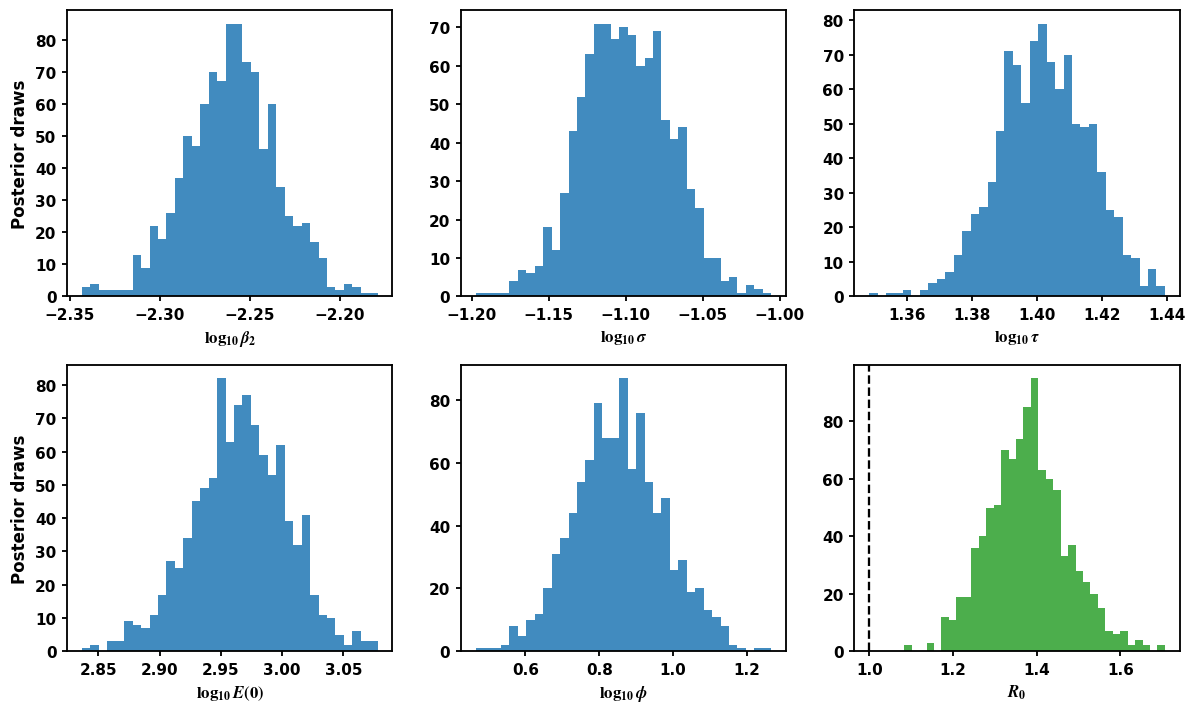

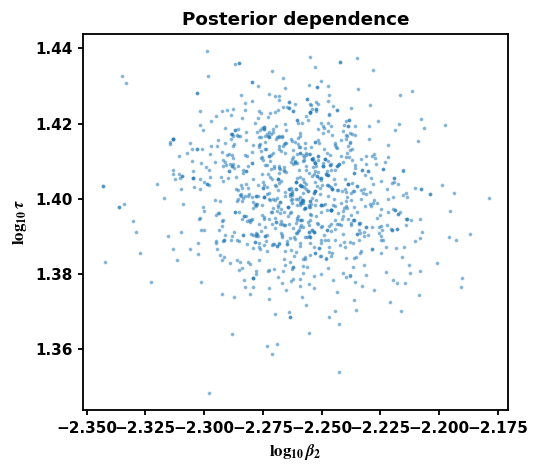

In [ ]:
def q(x, p): return np.percentile(x, p)
R0_post = np.array([R0_fn(*row[:3]) for row in POST])
tab = pd.DataFrame({"median": [q(POST[:, j], 50) for j in range(D)],
                    "2.5%": [q(POST[:, j], 2.5) for j in range(D)],
                    "97.5%": [q(POST[:, j], 97.5) for j in range(D)]}, index=LABELS)
tab.loc["R0"] = [q(R0_post, 50), q(R0_post, 2.5), q(R0_post, 97.5)]
display(tab.style.format("{:.5g}")) if "display" in globals() else print(tab)
print(f"P(R0 > 1 | D_train) = {(R0_post > 1).mean():.3f}")
# prior-bound check: posterior mass piled against a bound means the bound (i.e. the prior) is driving the result
for j, nm in enumerate(PNAMES):
    lo_f = (np.log(POST[:, j]) - LLOW[j]) / (LHIGH[j] - LLOW[j])
    if np.percentile(lo_f, 97.5) > 0.97 or np.percentile(lo_f, 2.5) < 0.03:
        print(f"*** WARNING: posterior of {nm} reaches its prior bound -> widen the bounds and rerun. ***")

TEXLAB = {"beta2": r"$\log_{10}\beta_2$", "sigma": r"$\log_{10}\sigma$", "tau": r"$\log_{10}\tau$",
          "E0": r"$\log_{10}E(0)$", "phi": r"$\log_{10}\phi$"}
panels, ncols = D + 1, 3
nrows = int(np.ceil(panels / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(11, 3.3 * nrows)); axes = np.atleast_1d(axes).ravel()
for j in range(D):
    axes[j].hist(np.log10(POST[:, j]), bins=35, color="C0", alpha=.85); axes[j].set_xlabel(TEXLAB[LABELS[j]])
axes[D].hist(R0_post, bins=35, color="C2", alpha=.85); axes[D].axvline(1, c="k", ls="--"); axes[D].set_xlabel(r"$R_0$")
for k in range(panels, len(axes)): axes[k].axis("off")
for r_ in range(nrows): axes[r_ * ncols].set_ylabel("Posterior draws")
savefig("fig06_posteriors.png")

if D >= 2:
    fig, ax = plt.subplots(figsize=(5, 4.4)); ax.plot(np.log10(POST[:, 0]), np.log10(POST[:, 2]), ".", ms=3, alpha=.4)
    ax.set_xlabel(r"$\log_{10}\beta_2$"); ax.set_ylabel(r"$\log_{10}\tau$"); ax.set_title("Posterior dependence"); savefig("fig07_beta2_tau.png")

## Block 10 — Stage 4a: posterior-predictive forecast from the Bayesian SEIR

For each posterior draw: solve the ODE over weeks 1–72 (mean curve), then draw a Negative-Binomial observation. We report
* the **credible band of the mean curve** $I(t;\theta)$ (parameter uncertainty only), and
* the **95% prediction interval for new observations** (parameter + observation uncertainty), used for coverage/AIW.

$$\text{Coverage}=\tfrac1{18}\sum_{t=55}^{72}\mathbf 1\{L_t\le Y_t\le U_t\},\qquad \text{AIW}=\tfrac1{18}\sum_{t=55}^{72}(U_t-L_t).$$

usable posterior draws: 1000


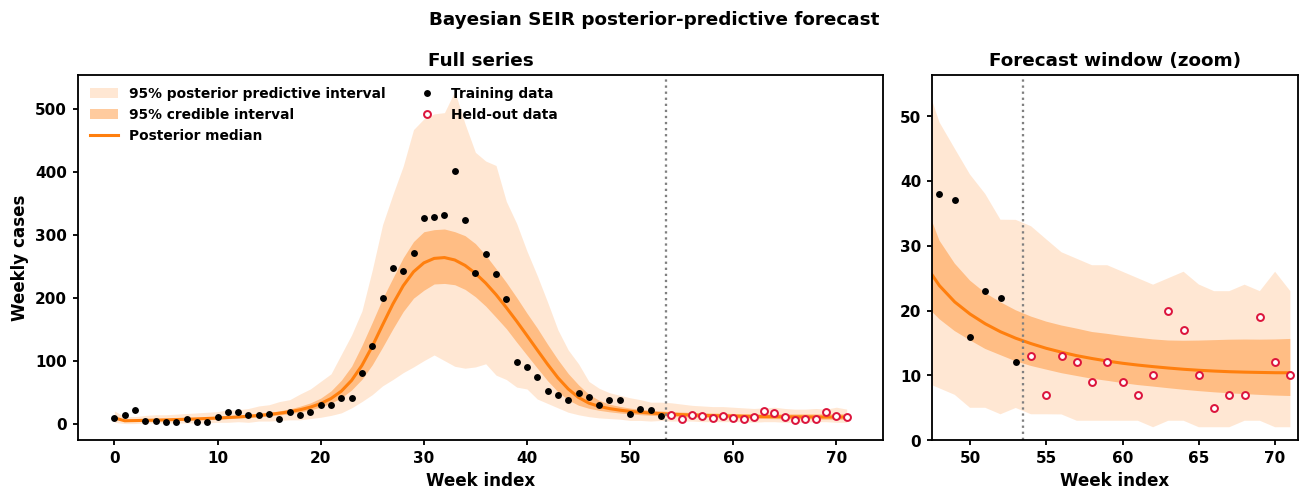

In [ ]:
def nb_sample(m, phi, r):
    lam = r.gamma(shape=phi, scale=np.maximum(m, 1e-8) / phi)
    return r.poisson(lam)

r_pp = np.random.default_rng(SEED + 7)
mean_curves, y_rep, keep = [], [], []
for row in POST:
    th, phi = row[:-1], row[-1]
    m = simulate(*split_theta(th), t_all)
    if np.any(np.isnan(m)): continue
    mean_curves.append(m); y_rep.append(nb_sample(m, phi, r_pp)); keep.append(True)
mean_curves, y_rep = np.array(mean_curves), np.array(y_rep)
print("usable posterior draws:", len(mean_curves))

bayes_point = np.median(mean_curves, 0)
band_lo, band_hi = np.percentile(mean_curves, [2.5, 97.5], 0)
pi_lo, pi_hi = np.percentile(y_rep, [2.5, 97.5], 0)
FORECASTS["Bayesian SEIR (posterior median)"] = dict(point=bayes_point, lo=pi_lo, hi=pi_hi)

c8 = COLORS["Bayesian SEIR (posterior median)"]
forecast_figure([("Posterior median", bayes_point, c8, "-")],
                [(pi_lo, pi_hi, c8, .18, "95% posterior predictive interval"), (band_lo, band_hi, c8, .40, "95% credible interval")],
                "fig08_bayes_predictive.png", "Bayesian SEIR posterior-predictive forecast")

## Block 11 — Stage 3/4b: Bayesian-uncertainty PINN ensemble

A PINN is trained for each of $K$ posterior draws $\theta^{(m)}$ (warm-started from the standard PINN, with that draw's ODE parameters and initial state fixed). The ensemble spread is the posterior-propagated PINN uncertainty. This is *Bayesian uncertainty around a PINN* — not a Bayesian neural network over network weights.

In [ ]:
if HAVE_TORCH and RUN_PINN_ENSEMBLE:
    import copy
    r_ens = np.random.default_rng(SEED + 11)
    sel = r_ens.choice(len(POST), size=min(K_ENSEMBLE, len(POST)), replace=False)
    ens_I, ens_phi = [], []
    t0 = time.time()
    for n_, s_ in enumerate(sel):
        th, phi = POST[s_][:-1], POST[s_][-1]
        b2, sg, ta, e0 = split_theta(th)
        X0_m = initial_state(e0)
        m = copy.deepcopy(pinn)
        train_pinn(m, to_torch_params(b2, sg, ta), X0_m, FT_EPOCHS, 5e-4, t_col, verbose=False)
        ens_I.append(pinn_I(m)); ens_phi.append(phi)
        print(f"ensemble member {n_+1}/{len(sel)} done ({time.time()-t0:.0f}s)")
    ens_I = np.array(ens_I)
    rep = np.array([nb_sample(ens_I[i], ens_phi[i], r_ens) for i in range(len(ens_I))])
    ens_point = np.median(ens_I, 0)
    e_lo, e_hi = np.percentile(rep, [2.5, 97.5], 0)
    FORECASTS["Bayesian-uncertainty PINN ensemble"] = dict(point=ens_point, lo=e_lo, hi=e_hi)
else:
    print("Skipped.")

ensemble member 1/20 done (9s)
ensemble member 2/20 done (18s)
ensemble member 3/20 done (27s)
ensemble member 4/20 done (36s)
ensemble member 5/20 done (45s)
ensemble member 6/20 done (55s)
ensemble member 7/20 done (63s)
ensemble member 8/20 done (72s)
ensemble member 9/20 done (82s)
ensemble member 10/20 done (90s)
ensemble member 11/20 done (99s)
ensemble member 12/20 done (109s)
ensemble member 13/20 done (117s)
ensemble member 14/20 done (127s)
ensemble member 15/20 done (136s)
ensemble member 16/20 done (145s)
ensemble member 17/20 done (154s)
ensemble member 18/20 done (163s)
ensemble member 19/20 done (176s)
ensemble member 20/20 done (185s)


## Block 12 — Final forecast comparison on the held-out 18 weeks (Figure 9, Table)

                                      RMSE     MAE  sMAPE_%  95%PI coverage  \
Mechanistic SEIR                     4.502   3.282   29.791             NaN   
Standard PINN                        4.843   3.498   31.282             NaN   
Bayesian SEIR (posterior median)     4.406   3.462   30.880             1.0   
Bayesian-uncertainty PINN ensemble   5.271   4.819   40.593             1.0   
Constant-mean baseline              78.737  78.630  156.678             NaN   

                                       AIW  
Mechanistic SEIR                       NaN  
Standard PINN                          NaN  
Bayesian SEIR (posterior median)    23.115  
Bayesian-uncertainty PINN ensemble  20.539  
Constant-mean baseline                 NaN  


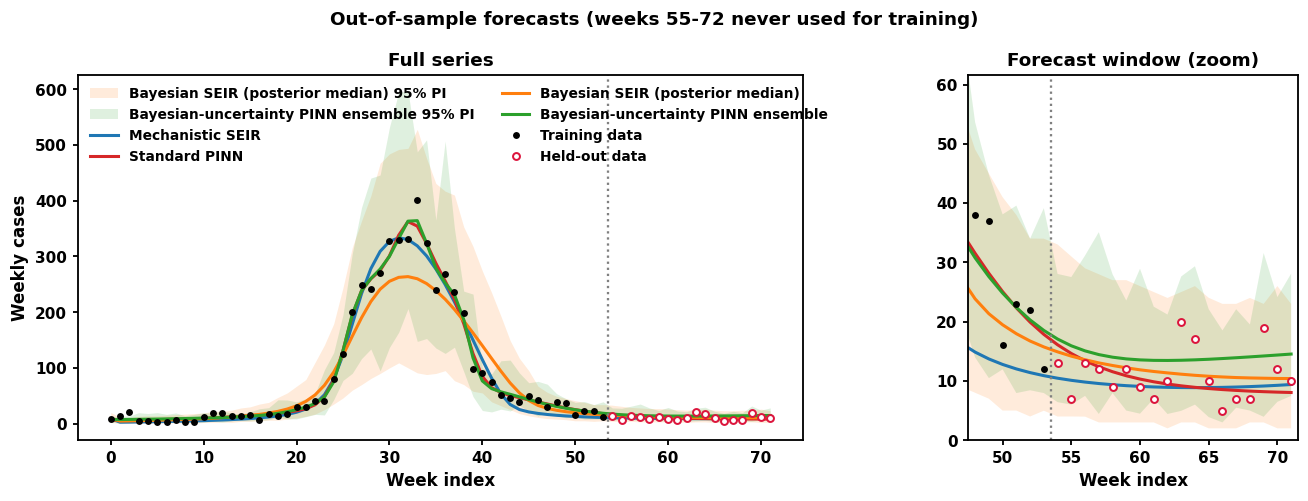

saved CSVs; figures in figures_brazil_full


In [ ]:
rows = {}
for name, f in FORECASTS.items():
    mt = metrics(y_test, f["point"][N_TRAIN:]); row = dict(mt)
    if f["lo"] is not None:
        lo, hi = f["lo"][N_TRAIN:], f["hi"][N_TRAIN:]
        row["95%PI coverage"] = float(np.mean((y_test >= lo) & (y_test <= hi)))
        row["AIW"] = float(np.mean(hi - lo))
    rows[name] = row
final_tab = pd.DataFrame(rows).T
final_tab.loc["Constant-mean baseline"] = {**metrics(y_test, np.full(N_TEST, y_train.mean()))}
display(final_tab.style.format("{:.3f}", na_rep="-")) if "display" in globals() else print(final_tab.round(3))

curves9 = [(n, f["point"], COLORS.get(n, "C4"), "-") for n, f in FORECASTS.items()]
bands9 = [(f["lo"], f["hi"], COLORS.get(n, "C4"), .15, n + " 95% PI") for n, f in FORECASTS.items() if f["lo"] is not None]
forecast_figure(curves9, bands9, "fig09_final_comparison.png", "Out-of-sample forecasts (weeks 55-72 never used for training)")

out = pd.DataFrame({"week_index": t_all, "week": df["Week"], "observed": y,
                    "set": ["train"] * N_TRAIN + ["test"] * N_TEST})
for name, f in FORECASTS.items():
    out[name] = f["point"]
    if f["lo"] is not None: out[name + " PI_lo"] = f["lo"]; out[name + " PI_hi"] = f["hi"]
out.to_csv("brazil_full_predictions.csv", index=False)
final_tab.to_csv("brazil_full_test_metrics.csv"); tab.to_csv("brazil_full_posterior_summary.csv"); calib.to_csv("brazil_full_mech_calibration.csv")
print("saved CSVs; figures in", FIG_DIR)

## Block 13 — Comparative study: what does each component contribute?

The central scientific question is

> *Does incorporating mechanistic structure and parameter uncertainty improve both predictive accuracy and uncertainty calibration?*

Four frameworks are compared on the **same** 54/18 split, with a data-only network as a no-mechanism reference. Blocks 13-18 answer the question with a capability matrix, metric tables with bar plots, a physics-weight ablation, a rolling-origin evaluation and robustness checks. Set `RUN_STUDIES = False` to skip them.

                         Mechanism Physics constraint Bayesian UQ  \
Data-only NN (reference)         —                  —           —   
SEIR                             ✓                  —           —   
SEIR + PINN                      ✓                  ✓           —   
SEIR + Bayesian UQ               ✓                  —           ✓   
Bayesian SEIR-PINN               ✓                  ✓           ✓   

                         Out-of-sample  
Data-only NN (reference)             ✓  
SEIR                                 ✓  
SEIR + PINN                          ✓  
SEIR + Bayesian UQ                   ✓  
Bayesian SEIR-PINN                   ✓  


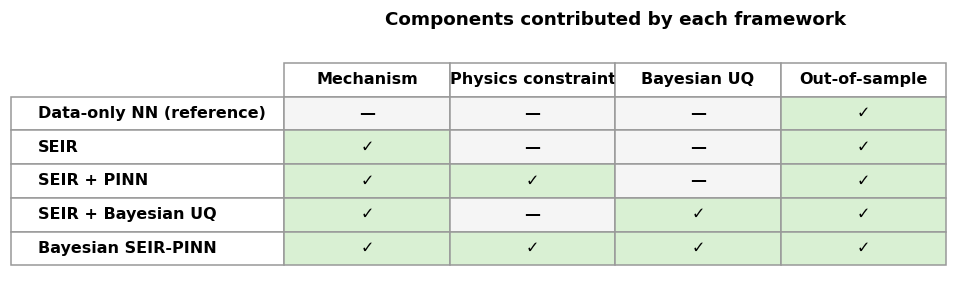

In [ ]:
CAP = pd.DataFrame(
    {"Mechanism":          ["—", "✓", "✓", "✓", "✓"],
     "Physics constraint": ["—", "—", "✓", "—", "✓"],
     "Bayesian UQ":        ["—", "—", "—", "✓", "✓"],
     "Out-of-sample":      ["✓", "✓", "✓", "✓", "✓"]},
    index=["Data-only NN (reference)", "SEIR", "SEIR + PINN", "SEIR + Bayesian UQ", "Bayesian SEIR-PINN"])
print(CAP)

fig, ax = plt.subplots(figsize=(8.8, 2.9)); ax.axis("off")
tb = ax.table(cellText=CAP.values, rowLabels=CAP.index, colLabels=CAP.columns, cellLoc="center", loc="center")
tb.auto_set_font_size(False); tb.set_fontsize(10.5); tb.scale(1, 1.7)
for (r_, c_), cell in tb.get_celld().items():
    if r_ > 0 and c_ >= 0:
        cell.set_facecolor("#d9f0d3" if cell.get_text().get_text() == "✓" else "#f5f5f5")
    cell.set_edgecolor("#999999")
ax.set_title("Components contributed by each framework", fontweight="bold", pad=4)
savefig("fig10_framework_matrix.png")
CAP_TEX = [r"{} & {} & {} & {} & {} \\".format(i, *[(r"\checkmark" if v == "✓" else "---") for v in row])
           for i, row in zip(CAP.index, CAP.values)]

## Block 14 — Shared helpers for the studies
Self-contained calibration, MCMC, classical (delta-method) uncertainty and proper scoring rules (95% interval score, CRPS). These do not modify the main pipeline's variables.

In [ ]:
def show(d):
    display(d) if "display" in globals() else print(d)

LOW_ALL, HIGH_ALL = np.array([1e-6, 1e-2, 1e-3, 1e-2]), np.array([1e-2, 2.0, 50.0, 3e3])

def sim_I_g(theta, I0_, N0_, t_eval):
    """theta = (beta2, sigma, tau, E0); returns I(t) on t_eval, NaN array if the solver fails."""
    b2, sg, ta, e0 = theta
    p = {**FIXED, "N0": N0_, "Lambda": mu * N0_, "beta2": b2, "sigma": sg, "tau": ta}
    try:
        sol = solve_ivp(lambda t, X: seir_rhs(t, X, p), (0.0, float(t_eval[-1])), [N0_ - e0 - I0_, e0, I0_, 0.0],
                        t_eval=t_eval, method="LSODA", rtol=1e-7, atol=1e-9)
        if (not sol.success) or sol.y.shape[1] != len(t_eval) or not np.all(np.isfinite(sol.y)): raise RuntimeError
        return sol.y[2]
    except Exception:
        return np.full(len(t_eval), np.nan)

def R0_g(b2, sg, ta, N0_):
    return N0_ * (FIXED["beta1"] / (sg + mu) + b2 * sg / ((sg + mu) * (mu + FIXED["delta"] + FIXED["gamma"] + ta)))

def calibrate_g(y_tr, N0_, est_E0, n_starts, seed, warm=()):
    """Bounded least-squares calibration on y_tr (many random starts + optional warm starts)."""
    n = len(y_tr); t = np.arange(n, dtype=float); I0_ = max(float(y_tr[0]), 1.0); scale = max(float(np.std(y_tr)), 1.0)
    k = 4 if est_E0 else 3; lo, hi = np.log(LOW_ALL[:k]), np.log(HIGH_ALL[:k])
    full = lambda z: (np.exp(z[0]), np.exp(z[1]), np.exp(z[2]), np.exp(z[3]) if est_E0 else I0_)
    def resid(z):
        p = sim_I_g(full(z), I0_, N0_, t)
        return np.full(n, 1e3) if np.any(np.isnan(p)) else (p - y_tr) / scale
    r = np.random.default_rng(seed)
    starts = [np.clip(np.log(np.asarray(w, float)[:k]), lo, hi) for w in warm] + [r.uniform(lo, hi) for _ in range(n_starts)]
    fits = []
    for z0 in starts:
        try: fits.append(least_squares(resid, z0, bounds=(lo, hi), method="trf", max_nfev=150))
        except Exception: pass
    if not fits: raise RuntimeError("calibration failed for all starts")
    fits.sort(key=lambda f: f.cost)
    b = least_squares(resid, fits[0].x, bounds=(lo, hi), method="trf", max_nfev=600, xtol=1e-12, ftol=1e-12, gtol=1e-12)
    edge = 0.01 * (hi - lo)
    return dict(z=b.x, theta=np.exp(b.x), cost=b.cost, jac=b.jac, scale=scale, n=n, k=k, lo=lo, hi=hi, I0=I0_, N0=N0_,
                est_E0=est_E0, full=full, at_bound=bool(np.any(b.x - lo < edge) or np.any(hi - b.x < edge)))

def loglik_g(y_tr, m, s, lik):
    m = np.maximum(m, 1e-8)
    if lik == "negbin": return nb_loglik(y_tr, m, s)
    return float(np.sum(-0.5 * np.log(2 * np.pi * s * s) - 0.5 * ((y_tr - m) / s) ** 2))

def mcmc_g(logpost, z0, lo, hi, n_iter, n_burn, seed):
    r = np.random.default_rng(seed); d = len(z0); z, lp = z0.copy(), logpost(z0)
    cov = np.diag(((hi - lo) * 0.01) ** 2); chain = np.empty((n_iter, d))
    for i in range(n_iter):
        if 500 <= i < n_burn and i % 250 == 0:
            cov = (2.38 ** 2 / d) * (np.cov(chain[max(0, i - 2000):i].T) + 1e-10 * np.eye(d))
        prop = r.multivariate_normal(z, cov); lpp = logpost(prop)
        if np.log(r.uniform()) < lpp - lp: z, lp = prop, lpp
        chain[i] = z
    return chain

def sample_obs(m, s, lik, r):
    if lik == "negbin": return r.poisson(r.gamma(shape=s, scale=np.maximum(m, 1e-8) / s))
    return np.maximum(m + r.normal(0, s, size=m.shape), 0.0)

def bayes_g(cal, y_all, n_train, H, lik, n_chains, n_iter, n_burn, n_draws, seed):
    """Bayesian calibration on y_all[:n_train] (log-uniform priors on the calibration bounds) and posterior-predictive
    forecast over weeks 1..n_train+H. Returns curves/draws over the whole range."""
    y_tr = y_all[:n_train]; t_tr = np.arange(n_train, dtype=float); t_f = np.arange(n_train + H, dtype=float)
    I0_, N0_, k = cal["I0"], cal["N0"], cal["k"]
    lo = np.append(cal["lo"], np.log(0.1)); hi = np.append(cal["hi"], np.log(1e3 if lik == "negbin" else 500.0))
    def logpost(z):
        if np.any(z < lo) or np.any(z > hi): return -np.inf
        pred = sim_I_g(cal["full"](z[:k]), I0_, N0_, t_tr)
        return -np.inf if np.any(np.isnan(pred)) else loglik_g(y_tr, pred, np.exp(z[-1]), lik)
    s0 = 20.0 if lik == "negbin" else max(1.0, cal["scale"] * np.sqrt(2 * cal["cost"] / n_train))
    z_start = np.append(cal["z"], np.log(s0)); chains = []
    for c in range(n_chains):
        for a in range(30):
            z_init = np.clip(z_start + np.random.default_rng(seed + 31 * a + c).normal(0, 0.05, len(z_start)), lo + 1e-3, hi - 1e-3)
            if np.isfinite(logpost(z_init)): break
        chains.append(mcmc_g(logpost, z_init, lo, hi, n_iter, n_burn, seed + 1000 + c))
    post = np.array(chains)[:, n_burn:, :]; d = post.shape[2]
    rhat = max(split_rhat(post[:, :, j]) for j in range(d)); ess = min(sum(ess_1d(post[c, :, j]) for c in range(n_chains)) for j in range(d))
    flat = np.exp(post.reshape(-1, d)); r = np.random.default_rng(seed + 5)
    flat = flat[r.choice(len(flat), size=min(n_draws, len(flat)), replace=False)]
    curves, reps, r0 = [], [], []
    for row in flat:
        th = cal["full"](np.log(row[:k]))
        m = sim_I_g(th, I0_, N0_, t_f)
        if np.any(np.isnan(m)): continue
        curves.append(m); reps.append(sample_obs(m, row[-1], lik, r)); r0.append(R0_g(th[0], th[1], th[2], N0_))
    curves, reps, r0 = np.array(curves), np.array(reps), np.array(r0)
    return dict(curves=curves, reps=reps, point=np.median(curves, 0), R0=r0, rhat=rhat, ess=ess, draws=flat)

def freq_uq_g(cal, n_train, H, n_draws, seed):
    """Classical (asymptotic / delta-method) uncertainty from the least-squares Jacobian, like the manuscript's CIs."""
    r = np.random.default_rng(seed + 9); t_f = np.arange(n_train + H, dtype=float)
    dof = max(cal["n"] - cal["k"], 1); s2 = 2 * cal["cost"] / dof
    cov = s2 * np.linalg.pinv(cal["jac"].T @ cal["jac"])
    zs = np.clip(r.multivariate_normal(cal["z"], cov, size=n_draws, check_valid="ignore"), cal["lo"], cal["hi"])
    curves = np.array([m for m in (sim_I_g(cal["full"](z), cal["I0"], cal["N0"], t_f) for z in zs) if not np.any(np.isnan(m))])
    reps = np.maximum(curves + r.normal(0, cal["scale"] * np.sqrt(s2), curves.shape), 0.0)
    return dict(curves=curves, reps=reps, point=sim_I_g(cal["full"](cal["z"]), cal["I0"], cal["N0"], t_f))

def pi_scores(y_true, lo, hi, alpha=0.05):
    cov = float(np.mean((y_true >= lo) & (y_true <= hi))); aiw = float(np.mean(hi - lo))
    iscore = float(np.mean((hi - lo) + (2 / alpha) * np.maximum(lo - y_true, 0) + (2 / alpha) * np.maximum(y_true - hi, 0)))
    return cov, aiw, iscore

def crps_samples(y_true, S):
    """Empirical CRPS from predictive samples S (m x T); for a point forecast CRPS = absolute error."""
    m = S.shape[0]; Ss = np.sort(S, axis=0); w = (2 * np.arange(1, m + 1) - m - 1)[:, None]
    e_xy = np.mean(np.abs(S - y_true[None, :]), axis=0); e_xx = 2 * np.sum(w * Ss, axis=0) / m ** 2
    return float(np.mean(e_xy - 0.5 * e_xx))

def score_window(y_true, point, samples=None):
    row = dict(metrics(y_true, point))
    if samples is not None:
        lo, hi = np.percentile(samples, [2.5, 97.5], axis=0)
        row["Coverage"], row["AIW"], row["IS"] = pi_scores(y_true, lo, hi); row["CRPS"] = crps_samples(y_true, samples)
    else:
        row.update(Coverage=np.nan, AIW=np.nan, IS=np.nan, CRPS=row["MAE"])
    return row

FAMILY_COLOR = {"Training mean": "#9e9e9e", "Persistence": "#bdbdbd", "Data-only": "#8e6bbf", "SEIR (least": "C0",
                "SEIR + classical": "#5fa8d3", "Standard PINN": "C3", "Bayesian SEIR": "C1", "Bayesian SEIR-PINN": "C2"}
def fam_color(name):
    for key in ["Bayesian SEIR-PINN", "SEIR + classical", "Data-only", "Persistence", "Training mean", "Standard PINN", "Bayesian SEIR", "SEIR (least"]:
        if name.startswith(key): return FAMILY_COLOR[key]
    return "C4"

## Block 15 — Ablation A: physics-constraint weight (needs PyTorch)

> Add blockquote


Re-trains the PINN with $w_p\in\{0,0.1,1,10\}$ from the same initialisation. $w_p=0$ is a data-only network with the same architecture, so the comparison isolates what the SEIR physics adds.

In [ ]:
PHYS_SWEEP, PHYS_FINAL = {}, {}
if HAVE_TORCH and RUN_STUDIES:
    _w_save = W_PHYS
    for wp in PHYS_W_LIST:
        torch.manual_seed(SEED); np.random.seed(SEED)          # same initialisation for every weight -> clean ablation
        W_PHYS = wp                                            # train_pinn reads this global
        m_ = PINN().to(device)
        h_ = train_pinn(m_, p_mech_t, X_mech_all[0], PINN_EPOCHS, 2e-3, t_col, verbose=False)
        PHYS_SWEEP[wp] = pinn_I(m_); PHYS_FINAL[wp] = float(h_[-1, 2])
        print(f"w_phys = {wp:<5g} done | final (unweighted) physics residual {h_[-1, 2]:.3e}")
    W_PHYS = _w_save
else:
    print("Skipped (needs PyTorch and RUN_STUDIES=True).")

w_phys = 0     done | final (unweighted) physics residual 3.786e+00
w_phys = 0.1   done | final (unweighted) physics residual 9.529e-03
w_phys = 1     done | final (unweighted) physics residual 1.288e-03
w_phys = 10    done | final (unweighted) physics residual 2.528e-04


           train RMSE  test RMSE  test MAE  test sMAPE_%  \
w_p = 0       13.3522     4.4386    3.2324       28.8789   
w_p = 0.1     14.5020     8.8415    8.0332       57.4881   
w_p = 1       13.4653     4.8433    3.4977       31.2816   
w_p = 10      13.7102     7.0063    6.3373       49.4095   

           final physics residual  
w_p = 0                    3.7858  
w_p = 0.1                  0.0095  
w_p = 1                    0.0013  
w_p = 10                   0.0003  


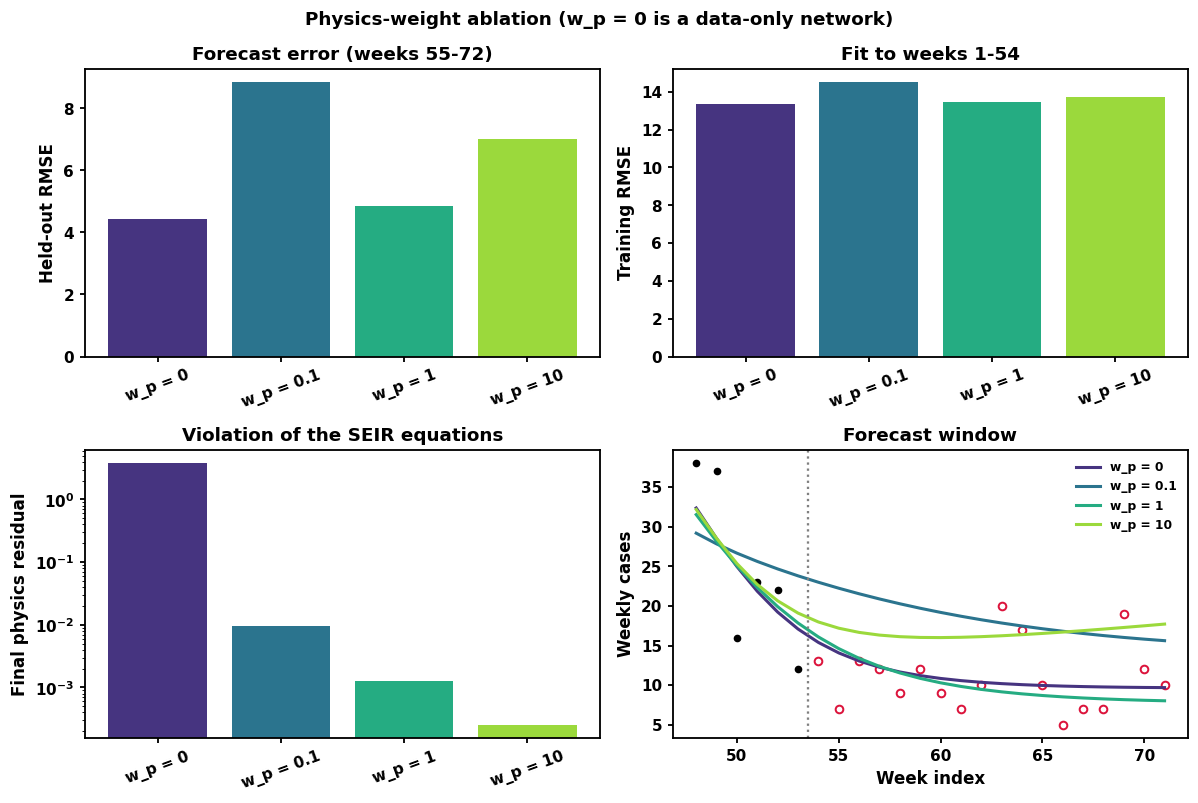

In [ ]:
if PHYS_SWEEP:
    rows = {}
    for wp, yp in PHYS_SWEEP.items():
        tr, te = metrics(y_train, yp[:N_TRAIN]), metrics(y_test, yp[N_TRAIN:])
        rows[f"w_p = {wp:g}"] = {"train RMSE": tr["RMSE"], "test RMSE": te["RMSE"], "test MAE": te["MAE"],
                                 "test sMAPE_%": te["sMAPE_%"], "final physics residual": PHYS_FINAL[wp]}
    phys_tab = pd.DataFrame(rows).T; show(phys_tab.round(4)); phys_tab.to_csv("brazil_physics_weight_ablation.csv")

    labs = list(rows); cols = plt.cm.viridis(np.linspace(0.15, 0.85, len(labs)))
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.4)); axes = axes.ravel()
    axes[0].bar(labs, phys_tab["test RMSE"], color=cols); axes[0].set_ylabel("Held-out RMSE"); axes[0].set_title("Forecast error (weeks 55-72)")
    axes[1].bar(labs, phys_tab["train RMSE"], color=cols); axes[1].set_ylabel("Training RMSE"); axes[1].set_title("Fit to weeks 1-54")
    axes[2].bar(labs, phys_tab["final physics residual"], color=cols); axes[2].set_yscale("log")
    axes[2].set_ylabel("Final physics residual"); axes[2].set_title("Violation of the SEIR equations")
    z0_ = max(0, N_TRAIN - 6)
    axes[3].plot(t_train[z0_:], y_train[z0_:], "ko", ms=4); axes[3].plot(t_test, y_test, "o", mfc="white", mec="crimson", ms=5, mew=1.3)
    for (wp, yp), c in zip(PHYS_SWEEP.items(), cols): axes[3].plot(t_all[z0_:], yp[z0_:], c=c, lw=2, label=f"w_p = {wp:g}")
    axes[3].axvline(N_TRAIN - .5, ls=":", c="gray"); axes[3].set_xlabel("Week index"); axes[3].set_ylabel("Weekly cases")
    axes[3].set_title("Forecast window"); axes[3].legend(frameon=False, fontsize=8)
    for a in axes[:3]: a.tick_params(axis="x", rotation=20)
    fig.suptitle("Physics-weight ablation (w_p = 0 is a data-only network)", fontweight="bold")
    savefig("fig13_physics_weight.png")
else:
    print("No physics-weight results (PyTorch unavailable or RUN_STUDIES=False).")

## Block 16 — Ablation B: framework comparison, bar plots and component contributions (Figures 11-12)
Accuracy (RMSE, MAE, sMAPE) and uncertainty quality (coverage, interval width, interval score, CRPS) for every framework on weeks 55-72, a paired bootstrap of the error differences, and the contribution of each component.

Held-out weeks 55-72.  IS = 95% interval score, CRPS for a point forecast equals its MAE.
                               RMSE     MAE  sMAPE_%  Coverage     AIW  \
Training mean                78.737  78.630  156.678       NaN     NaN   
Persistence (last value)      4.210   3.389   30.567       NaN     NaN   
Data-only NN (w_p=0)          4.439   3.232   28.879       NaN     NaN   
SEIR (least squares)          4.502   3.282   29.791       NaN     NaN   
SEIR + classical UQ           4.502   3.282   29.791       1.0  48.867   
Standard PINN                 4.843   3.498   31.282       NaN     NaN   
Bayesian SEIR (NegBin)        4.406   3.462   30.880       1.0  23.115   
Bayesian SEIR-PINN ensemble   5.271   4.819   40.593       1.0  20.539   

                                 IS    CRPS  dRMSE_vs_SEIR_%  
Training mean                   NaN  78.630         1649.028  
Persistence (last value)        NaN   3.389           -6.485  
Data-only NN (w_p=0)            NaN   3.232           

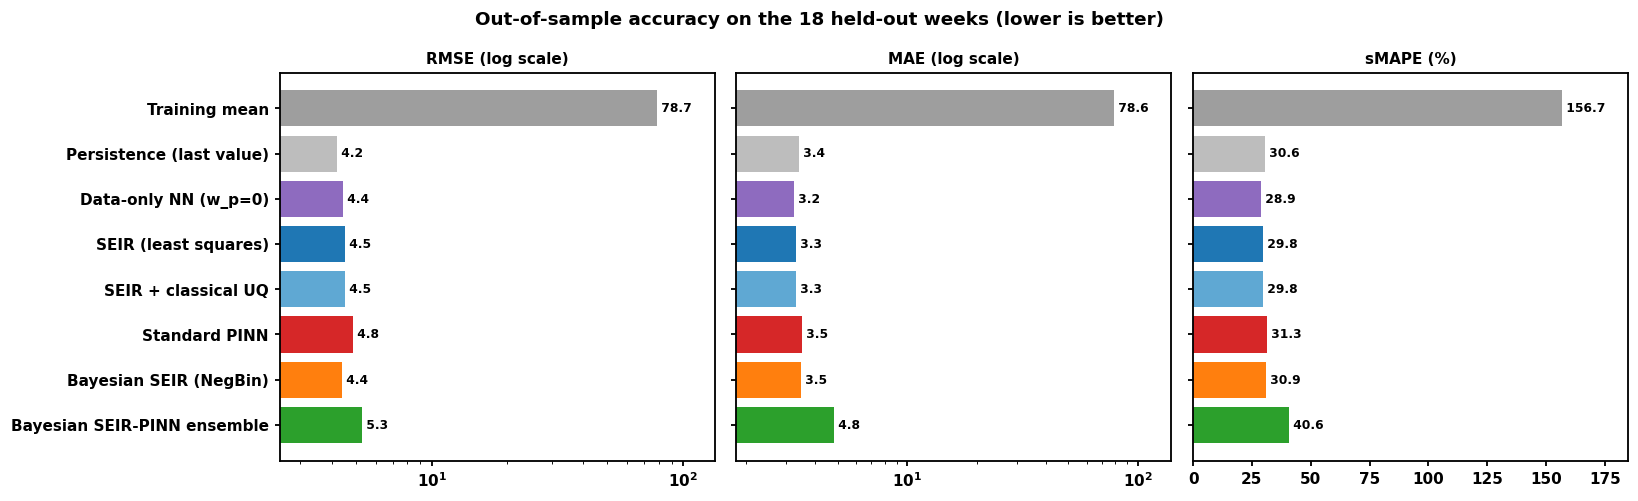

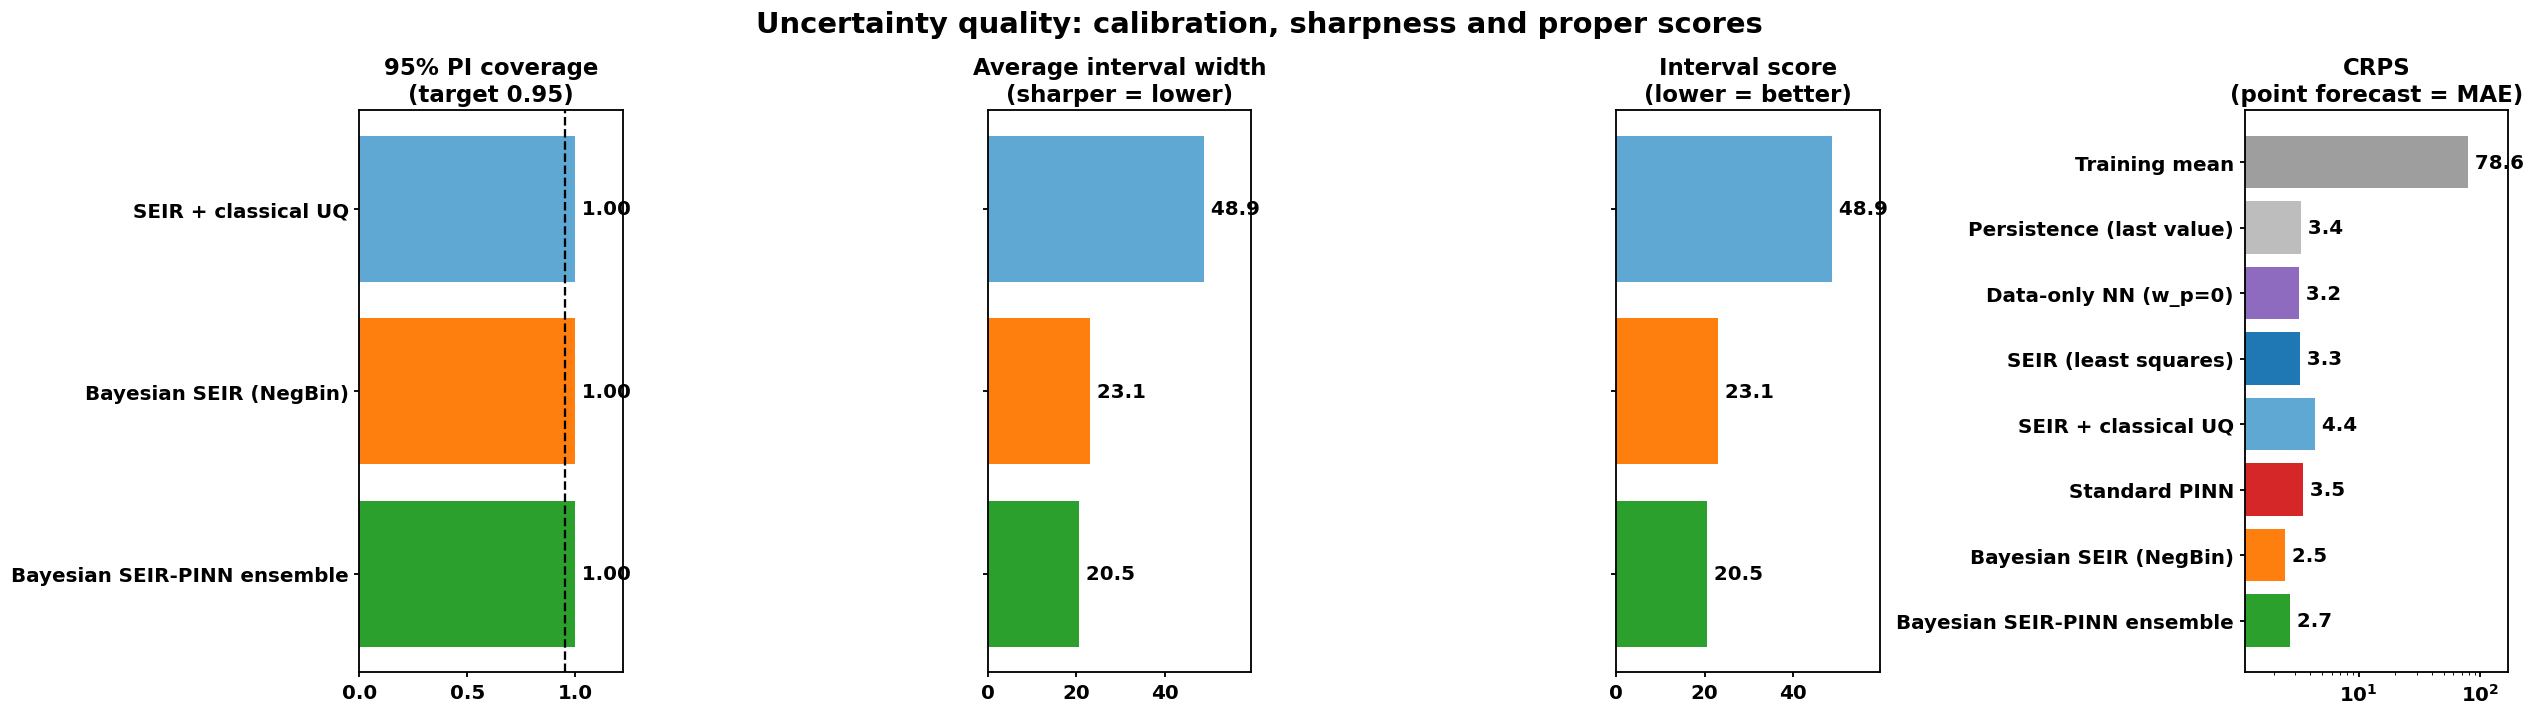


Contribution of each component (after - before; for RMSE/MAE/AIW/IS/CRPS negative = improvement, for coverage closer to +0.95 = better):
                                                  dRMSE   dMAE  dCoverage  \
Contribution                                                                
Mechanism: data-only NN -> SEIR                   0.063  0.050        NaN   
Physics: SEIR -> SEIR + PINN                      0.342  0.215        NaN   
Parameter UQ: classical -> Bayesian              -0.096  0.180        0.0   
Integration: PINN -> Bayesian SEIR-PINN           0.428  1.321        NaN   
Integration: Bayesian SEIR -> Bayesian SEIR-PINN  0.865  1.357        0.0   

                                                    dAIW     dIS  dCRPS  
Contribution                                                             
Mechanism: data-only NN -> SEIR                      NaN     NaN  0.050  
Physics: SEIR -> SEIR + PINN                         NaN     NaN  0.215  
Parameter UQ: classical ->

In [ ]:
sl = slice(N_TRAIN, N)
methods = {}
def add(name, point, samples=None):
    methods[name] = (np.asarray(point, float), None if samples is None else np.asarray(samples, float))

add("Training mean", np.full(N, y_train.mean()))
add("Persistence (last value)", np.full(N, y_train[-1]))
if PHYS_SWEEP and 0.0 in PHYS_SWEEP: add("Data-only NN (w_p=0)", PHYS_SWEEP[0.0])
add("SEIR (least squares)", FORECASTS["Mechanistic SEIR"]["point"])

# classical (non-Bayesian) uncertainty for the SAME mechanistic fit, built from the least-squares Jacobian
cal_main = dict(z=best.x, jac=best.jac, cost=best.cost, scale=SCALE, n=N_TRAIN, k=len(PNAMES), lo=LLOW, hi=LHIGH,
                I0=max(float(y_train[0]), 1.0), N0=N0, est_E0=ESTIMATE_E0, full=lambda z: split_theta(np.exp(z)))
fq_main = freq_uq_g(cal_main, N_TRAIN, N_TEST, max(STUDY_DRAWS, 500), SEED)
add("SEIR + classical UQ", fq_main["point"], fq_main["reps"])
if "Standard PINN" in FORECASTS: add("Standard PINN", FORECASTS["Standard PINN"]["point"])
add("Bayesian SEIR (NegBin)", bayes_point, y_rep)
if "Bayesian-uncertainty PINN ensemble" in FORECASTS and "rep" in globals():
    add("Bayesian SEIR-PINN ensemble", ens_point, rep)

rows = {n: score_window(y_test, pt[sl], None if sm is None else sm[:, sl]) for n, (pt, sm) in methods.items()}
cmp_tab = pd.DataFrame(rows).T[["RMSE", "MAE", "sMAPE_%", "Coverage", "AIW", "IS", "CRPS"]]
cmp_tab["dRMSE_vs_SEIR_%"] = 100 * (cmp_tab["RMSE"] / cmp_tab.loc["SEIR (least squares)", "RMSE"] - 1)
print("Held-out weeks 55-72.  IS = 95% interval score, CRPS for a point forecast equals its MAE.")
show(cmp_tab.round(3)); cmp_tab.to_csv("brazil_comparison_table.csv")

# how much of any difference can be trusted with only 18 test points? paired bootstrap of absolute errors vs SEIR
idx = np.random.default_rng(SEED).integers(0, N_TEST, size=(3000, N_TEST))
ae = {k: np.abs(v[0][sl] - y_test) for k, v in methods.items()}; ref = ae["SEIR (least squares)"]
boot = {k: (float((a - ref).mean()), *np.percentile((a - ref)[idx].mean(1), [2.5, 97.5])) for k, a in ae.items()}
boot_tab = pd.DataFrame(boot, index=["dMAE vs SEIR", "2.5%", "97.5%"]).T
print("\nPaired bootstrap of MAE difference vs SEIR (negative = better; interval containing 0 = not distinguishable):")
show(boot_tab.round(3)); boot_tab.to_csv("brazil_comparison_bootstrap.csv")

# ---- Figure 11: accuracy bars
names = list(cmp_tab.index); cols = [fam_color(n) for n in names]
def hbar(ax, labs, vals, ttl, log=False, vline=None, show_labels=True, fmt_="{:.1f}", fs_val=8, fs_title=10, fs_tick=None):
    ax.barh(range(len(labs)), vals, color=[fam_color(n) for n in labs]); ax.set_yticks(range(len(labs)))
    ax.set_yticklabels(labs if show_labels else [""] * len(labs))
    if log: ax.set_xscale("log")
    if vline is not None: ax.axvline(vline, c="k", ls="--", lw=1.5 if fs_tick else 1)
    for i, x in enumerate(vals):
        if np.isfinite(x): ax.text(x, i, " " + fmt_.format(x), va="center", fontsize=fs_val)
    ax.margins(x=0.22 if fs_tick else 0.18); ax.set_title(ttl, fontsize=fs_title); ax.invert_yaxis()
    if fs_tick: ax.tick_params(axis="both", labelsize=fs_tick)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
hbar(axes[0], names, cmp_tab["RMSE"].values, "RMSE (log scale)", log=True)
hbar(axes[1], names, cmp_tab["MAE"].values, "MAE (log scale)", log=True, show_labels=False)
hbar(axes[2], names, cmp_tab["sMAPE_%"].values, "sMAPE (%)", show_labels=False)
fig.suptitle("Out-of-sample accuracy on the 18 held-out weeks (lower is better)", fontweight="bold")
savefig("fig11_metric_comparison.png")

# ---- Figure 12: uncertainty quality (ONLY this figure uses larger fonts)
FS12 = dict(fs_val=13, fs_title=15, fs_tick=13)
prob = cmp_tab.dropna(subset=["Coverage"]).index.tolist()
fig, axes = plt.subplots(1, 4, figsize=(23, 6.6))
hbar(axes[0], prob, cmp_tab.loc[prob, "Coverage"].values, "95% PI coverage\n(target 0.95)", vline=0.95, fmt_="{:.2f}", **FS12)
hbar(axes[1], prob, cmp_tab.loc[prob, "AIW"].values, "Average interval width\n(sharper = lower)", show_labels=False, **FS12)
hbar(axes[2], prob, cmp_tab.loc[prob, "IS"].values, "Interval score\n(lower = better)", show_labels=False, **FS12)
hbar(axes[3], names, cmp_tab["CRPS"].values, "CRPS\n(point forecast = MAE)", log=True, fmt_="{:.1f}", **FS12)
fig.suptitle("Uncertainty quality: calibration, sharpness and proper scores", fontsize=19, fontweight="bold")
savefig("fig12_uq_calibration.png")

# ---- what does each component contribute?  (delta = after - before; negative error/score change = improvement)
pairs = [("Mechanism: data-only NN -> SEIR", "Data-only NN (w_p=0)", "SEIR (least squares)"),
         ("Physics: SEIR -> SEIR + PINN", "SEIR (least squares)", "Standard PINN"),
         ("Parameter UQ: classical -> Bayesian", "SEIR + classical UQ", "Bayesian SEIR (NegBin)"),
         ("Integration: PINN -> Bayesian SEIR-PINN", "Standard PINN", "Bayesian SEIR-PINN ensemble"),
         ("Integration: Bayesian SEIR -> Bayesian SEIR-PINN", "Bayesian SEIR (NegBin)", "Bayesian SEIR-PINN ensemble")]
crow = [dict(Contribution=lab, **{"d" + c: cmp_tab.loc[b, c] - cmp_tab.loc[a, c] for c in ["RMSE", "MAE", "Coverage", "AIW", "IS", "CRPS"]})
        for lab, a, b in pairs if a in cmp_tab.index and b in cmp_tab.index]
contrib_tab = pd.DataFrame(crow).set_index("Contribution")
print("\nContribution of each component (after - before; for RMSE/MAE/AIW/IS/CRPS negative = improvement, for coverage closer to +0.95 = better):")
show(contrib_tab.round(3)); contrib_tab.to_csv("brazil_component_contributions.csv")

## Block 17 — Study C (revised): rolling-origin evaluation, every eligible model refitted at every origin
The 54/18 split puts only the post-epidemic tail in the test window (all 18 held-out weeks are low-activity), and the original origin grid (weeks 30-60) contained **no growth-phase target weeks**. This block
1. adds earlier origins so that growth, peak, decline and low-activity weeks are all forecast (phases are defined objectively from the series: peak = cases >= 50% of the maximum, growth/decline = before/after the peak window with cases >= 10% of the maximum, low = the rest);
2. **refits every eligible model at every origin** using only the weeks available there: persistence, training mean, SEIR (least squares), SEIR + classical UQ, Bayesian SEIR, **data-only NN and standard PINN (several random initialisations per origin)**, and optionally the Bayesian SEIR-PINN ensemble (`RO_RUN_ENSEMBLE = True`, slow);
3. reports results **by forecast horizon** (1-4, 5-8, 9-12 weeks) and **by epidemic phase** of the target week;
4. fixes a leak in the original block: `THETA4_MAIN` (fitted on weeks 1-54) was used as a warm start at every origin, including origins whose training window ends before week 54. It is now used only for origins >= 54.

Runtime: the NN/PINN refits dominate (origins x seeds x 2 models x `PINN_EPOCHS`); use a GPU or reduce `RO_SEEDS` / `PINN_EPOCHS` if needed.

phase of every week (index):  {'growth': [22, 23, 24, 25, 26], 'peak': [27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37], 'decline': [38, 39, 40, 41, 42, 43, 45, 46]} | 'low' = remaining weeks
target weeks per phase covered by the ORIGINAL origins {30,...,60}: {'growth': 0, 'peak': 10, 'decline': 16, 'low': 46}
target weeks per phase covered by the NEW origins                : {'growth': 13, 'peak': 39, 'decline': 17, 'low': 51}
origin 18 (targets 19-30, phases ['growth', 'low', 'peak']) done in 425s | R-hat 1.38 | at-bound True
origin 21 (targets 22-33, phases ['growth', 'low', 'peak']) done in 417s | R-hat 1.44 | at-bound False
origin 24 (targets 25-36, phases ['growth', 'peak']) done in 432s | R-hat 1.55 | at-bound False
origin 27 (targets 28-39, phases ['decline', 'peak']) done in 464s | R-hat 2.31 | at-bound False
origin 30 (targets 31-42, phases ['decline', 'peak']) done in 488s | R-hat 9.19 | at-bound True
origin 36 (targets 37-48, phases ['decline', 'low', 'peak']) done in 490s | R-

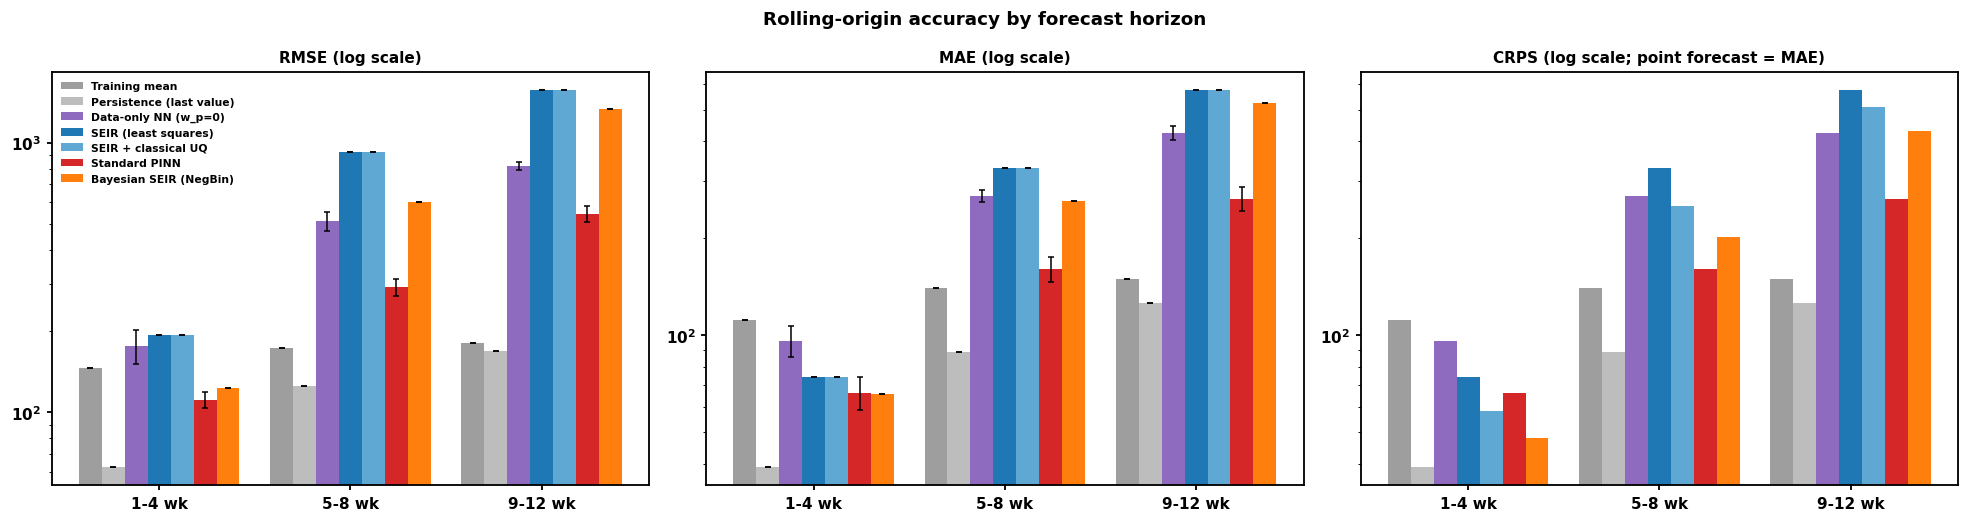

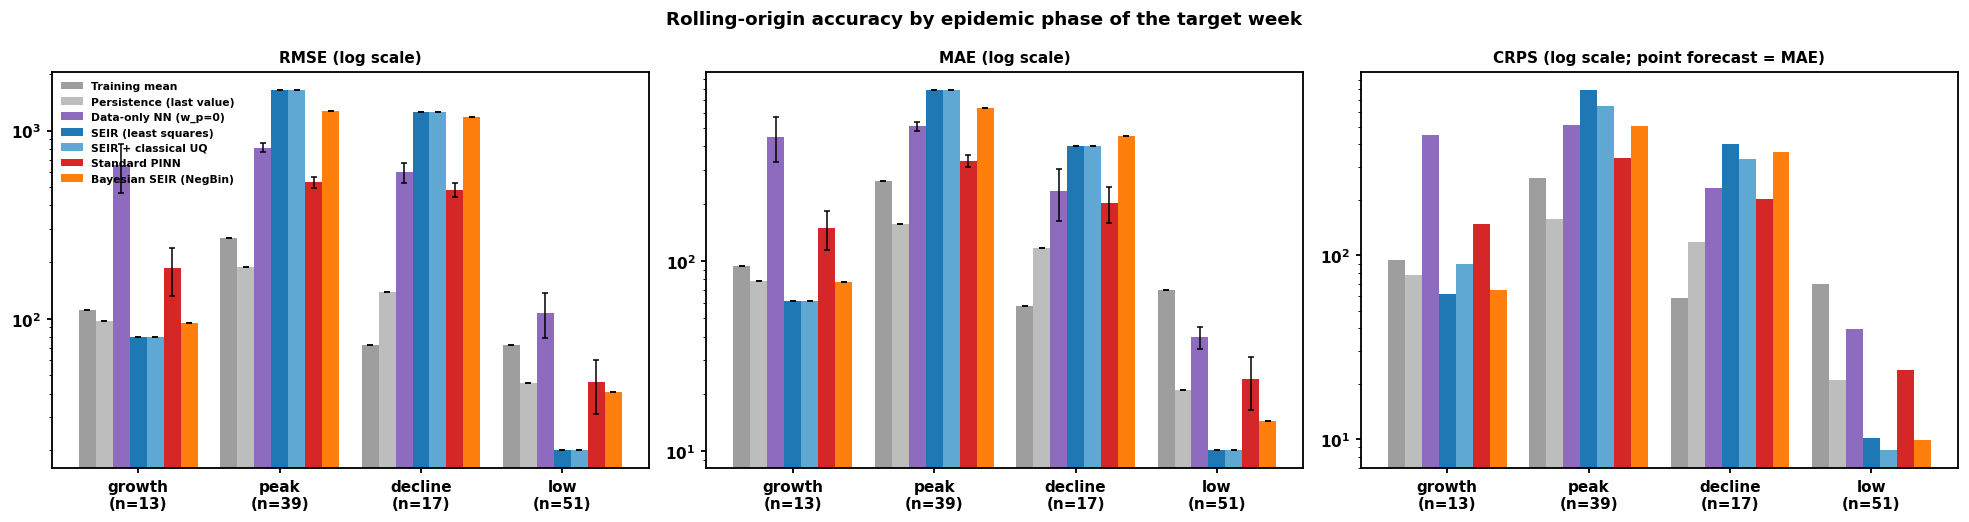

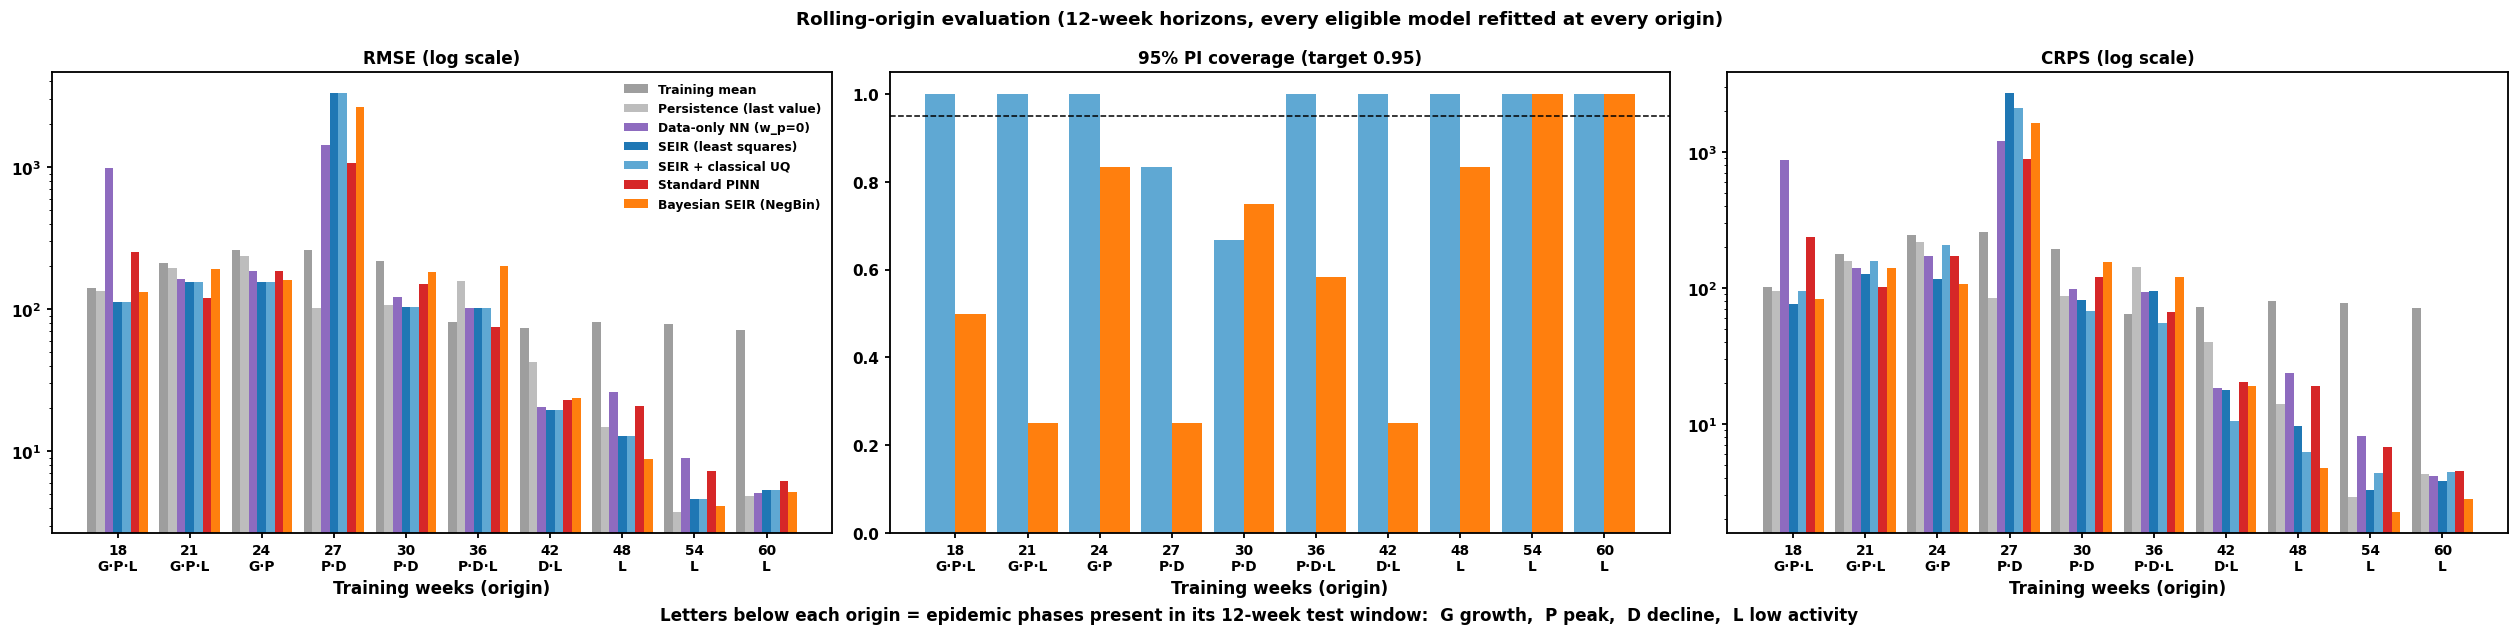


written: tex_snippets/tab_rolling_horizon.tex, tab_rolling_phase.tex; ro_macro feeds the existing tab_rolling_rows.tex (Block 18b)


In [ ]:
# =====================================================================================================
# BLOCK 17 (REVISED) - Study C: rolling-origin evaluation
#   * EVERY eligible model is refitted at EVERY origin (incl. data-only NN, standard PINN, optional ensemble)
#   * origins now include the epidemic GROWTH phase (the old grid started at week 30, after growth)
#   * results are reported by FORECAST HORIZON (1-4, 5-8, 9-12 weeks) and by EPIDEMIC PHASE
#   * neural models use several random initialisations per origin -> mean and sd over seeds
#   * FIX: THETA4_MAIN (fitted on weeks 1-54) is no longer used as a warm start at origins < 54
# =====================================================================================================
_pre_ro = dict(globals())      # snapshot: this block must not overwrite variables that other cells rely on
import copy
THETA4_MAIN = np.array([b2_m, s_m, tau_m, E0_m])      # main-pipeline calibration (weeks 1-54); see the warm-start rule below

RO_ORIGINS_EXT  = [24, 30, 54] if FAST_TEST else [18, 21, 24, 27, 30, 36, 42, 48, 54, 60]
RO_H            = 12
RO_SEEDS        = 2 if FAST_TEST else 5          # random initialisations per origin for NN / PINN
RO_RUN_NN       = HAVE_TORCH                      # retrain data-only NN and PINN at every origin
RO_RUN_ENSEMBLE = False                           # True: also refit the posterior-propagated PINN ensemble at every origin (slow)
RO_K_ENS        = 3 if FAST_TEST else 10          # ensemble members per origin
PHASE_LO_FRAC, PHASE_HI_FRAC = 0.10, 0.50         # phase thresholds, as a fraction of the series maximum (fixed a priori)
METHOD_ORDER = ["Training mean", "Persistence (last value)", "Data-only NN (w_p=0)", "SEIR (least squares)",
                "SEIR + classical UQ", "Standard PINN", "Bayesian SEIR (NegBin)", "Bayesian SEIR-PINN ensemble"]
PHASE_ORDER  = ["growth", "peak", "decline", "low"]
HBIN_ORDER   = ["1-4", "5-8", "9-12"]

# ---- objective epidemic phases, defined from the observed series only (used to LABEL target weeks, never to fit) ----
def classify_phases(y_series, lo_frac=PHASE_LO_FRAC, hi_frac=PHASE_HI_FRAC):
    """peak   : weeks with cases >= hi_frac * max
       growth : before the peak window and cases >= lo_frac * max
       decline: after the peak window and cases >= lo_frac * max
       low    : everything else (pre-epidemic baseline and post-epidemic tail)"""
    ymax = float(np.max(y_series)); hi, lo = hi_frac * ymax, lo_frac * ymax
    pk = np.where(y_series >= hi)[0]; first, last = pk.min(), pk.max()
    ph = np.empty(len(y_series), dtype=object)
    for t, v in enumerate(y_series):
        ph[t] = "peak" if v >= hi else ("growth" if (t < first and v >= lo) else ("decline" if (t > last and v >= lo) else "low"))
    return ph
PHASE = classify_phases(y)
print("phase of every week (index): ", {p: [int(i) for i in np.where(PHASE == p)[0]] for p in PHASE_ORDER if p != "low"}, "| 'low' = remaining weeks")
print("target weeks per phase covered by the ORIGINAL origins {30,...,60}:",
      {p: int(sum(PHASE[t] == p for o in [30, 36, 42, 48, 54, 60] for t in range(o, min(o + RO_H, N)))) for p in PHASE_ORDER})
print("target weeks per phase covered by the NEW origins                :",
      {p: int(sum(PHASE[t] == p for o in RO_ORIGINS_EXT for t in range(o, min(o + RO_H, N)))) for p in PHASE_ORDER})

# ---- NN / PINN trainer that takes its training data as arguments (the original train_pinn reads globals) ----
if HAVE_TORCH:
    def train_pinn_ro(model, p_t, U0_np, epochs, lr, t_col_, t_tr, y_tr, w_phys, y_ref):
        t_obs = torch.tensor(np.asarray(t_tr).reshape(-1, 1), dtype=dtype, device=device)
        y_obs = torch.tensor(np.asarray(y_tr).reshape(-1, 1), dtype=dtype, device=device)
        U0 = torch.tensor(U0_np.reshape(1, -1) / N0, dtype=dtype, device=device); t0 = torch.zeros(1, 1, dtype=dtype, device=device)
        opt = optim.Adam(model.parameters(), lr=lr); sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=lr * 0.02)
        for _ in range(epochs):
            opt.zero_grad()
            L_data = torch.mean(((N0 * model(t_obs)[:, 2:3] - y_obs) / y_ref) ** 2)
            tc = t_col_.clone().requires_grad_(True); Uc = model(tc)
            L_phys = torch.mean(((d_dt(Uc, tc) - ode_rhs_scaled(Uc, p_t)) / C_VEC) ** 2)
            L_ic = torch.mean(((model(t0) - U0) / C_VEC) ** 2)
            (W_DATA * L_data + w_phys * L_phys + W_IC * L_ic).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step(); sch.step()

    @torch.no_grad()
    def net_I(model, t_vec):
        model.eval(); tt = torch.tensor(np.asarray(t_vec).reshape(-1, 1), dtype=dtype, device=device)
        return (N0 * model(tt)[:, 2]).cpu().numpy()

# ---- main loop: refit everything at every origin using ONLY the weeks available at that origin ----
RO_STORE, RO_META = {}, []                   # (origin, method, seed) -> dict(point, samples);  per-origin diagnostics
prev = []                                    # warm starts: ONLY solutions from earlier origins
for n_tr in RO_ORIGINS_EXT:
    H = min(RO_H, N - n_tr)
    if H <= 0: continue
    t0_ = time.time(); sl_ = slice(n_tr, n_tr + H)
    warm = list(prev) + ([THETA4_MAIN] if n_tr >= N_TRAIN else [])     # THETA4_MAIN only if its data window is contained in the origin's
    try:
        cal_o = calibrate_g(y[:n_tr], N0, True, STUDY_STARTS, SEED + n_tr, warm=warm)
        bay   = bayes_g(cal_o, y, n_tr, H, "negbin", STUDY_CHAINS, STUDY_ITER, STUDY_BURN, STUDY_DRAWS, SEED + n_tr)
        fq    = freq_uq_g(cal_o, n_tr, H, STUDY_DRAWS, SEED + n_tr)
    except Exception as e:
        print(f"origin {n_tr}: FAILED ({type(e).__name__}: {e})"); continue
    prev = [cal_o["theta"]]

    def put(name, seed, pt, sm=None):
        RO_STORE[(n_tr, name, seed)] = dict(point=np.asarray(pt, float)[sl_], samples=None if sm is None else np.asarray(sm, float)[:, sl_])
    put("Training mean", 0, np.full(n_tr + H, y[:n_tr].mean()))
    put("Persistence (last value)", 0, np.full(n_tr + H, y[n_tr - 1]))
    put("SEIR (least squares)", 0, fq["point"])
    put("SEIR + classical UQ", 0, fq["point"], fq["reps"])
    put("Bayesian SEIR (NegBin)", 0, bay["point"], bay["reps"])

    if RO_RUN_NN:
        b2_, sg_, ta_, e0_ = cal_o["theta"][:4]
        p_t_, U0_ = to_torch_params(b2_, sg_, ta_), initial_state(e0_)
        y_ref_ = max(float(np.max(y[:n_tr])), 10.0)                    # scale from the available data only
        rng_c = np.random.default_rng(SEED + n_tr)
        t_col_ = torch.tensor(np.sort(rng_c.uniform(0, n_tr + H - 1, N_COLLOC)).reshape(-1, 1), dtype=dtype, device=device)  # physics-only points; no future observations
        t_tr_, t_grid_ = np.arange(n_tr, dtype=float), np.arange(n_tr + H, dtype=float)
        base_pinn = None
        for s in range(RO_SEEDS):
            for name, wp in [("Data-only NN (w_p=0)", 0.0), ("Standard PINN", W_PHYS)]:
                torch.manual_seed(SEED + 1000 * s + n_tr)
                m_ = PINN().to(device)
                train_pinn_ro(m_, p_t_, U0_, PINN_EPOCHS, 2e-3, t_col_, t_tr_, y[:n_tr], wp, y_ref_)
                put(name, s, net_I(m_, t_grid_))
                if name == "Standard PINN" and s == 0: base_pinn = m_
        if RO_RUN_ENSEMBLE and base_pinn is not None:
            r_e = np.random.default_rng(SEED + 11 + n_tr)
            idx = r_e.choice(len(bay["draws"]), size=min(RO_K_ENS, len(bay["draws"])), replace=False)
            ens_I_, ens_phi_ = [], []
            for j in idx:
                row = bay["draws"][j]; b2j, sgj, taj, e0j = cal_o["full"](np.log(row[:cal_o["k"]]))
                mm = copy.deepcopy(base_pinn)
                train_pinn_ro(mm, to_torch_params(b2j, sgj, taj), initial_state(e0j), FT_EPOCHS, 5e-4, t_col_, t_tr_, y[:n_tr], W_PHYS, y_ref_)
                ens_I_.append(net_I(mm, t_grid_)); ens_phi_.append(row[-1])
            ens_I_ = np.array(ens_I_); rep_ = np.array([nb_sample(ens_I_[i], ens_phi_[i], r_e) for i in range(len(ens_I_))])
            put("Bayesian SEIR-PINN ensemble", 0, np.median(ens_I_, 0), rep_)
    RO_META.append(dict(origin=n_tr, horizon=H, rhat=bay["rhat"], at_bound=cal_o["at_bound"], seconds=time.time() - t0_))
    print(f"origin {n_tr:2d} (targets {n_tr+1}-{n_tr+H}, phases {sorted(set(PHASE[n_tr:n_tr+H]))}) done in {time.time()-t0_:.0f}s | R-hat {bay['rhat']:.2f} | at-bound {cal_o['at_bound']}")

# ---- tidy per-week scores ----
def crps_vec(y_true, S):
    m = S.shape[0]; Ss = np.sort(S, axis=0); w = (2 * np.arange(1, m + 1) - m - 1)[:, None]
    return np.mean(np.abs(S - y_true[None, :]), axis=0) - 0.5 * (2 * np.sum(w * Ss, axis=0) / m ** 2)

recs = []
for (n_tr, name, seed), d in RO_STORE.items():
    Hh = len(d["point"]); yt = y[n_tr:n_tr + Hh]; e = d["point"] - yt
    if d["samples"] is not None:
        lo, hi = np.percentile(d["samples"], [2.5, 97.5], axis=0); crps = crps_vec(yt, d["samples"])
        cov = ((yt >= lo) & (yt <= hi)).astype(float); aiw = hi - lo
        isc = (hi - lo) + (2 / 0.05) * np.maximum(lo - yt, 0) + (2 / 0.05) * np.maximum(yt - hi, 0)
    else:
        crps, cov, aiw, isc = np.abs(e), np.full(Hh, np.nan), np.full(Hh, np.nan), np.full(Hh, np.nan)
    for h in range(Hh):
        recs.append(dict(origin=n_tr, method=name, seed=seed, h=h + 1, target=n_tr + h, phase=PHASE[n_tr + h],
                         hbin=("1-4" if h < 4 else ("5-8" if h < 8 else "9-12")),
                         se=e[h] ** 2, ae=abs(e[h]), crps=crps[h], cover=cov[h], aiw=aiw[h], is_=isc[h]))
RO_LONG = pd.DataFrame(recs)
METHODS_PRESENT = [m for m in METHOD_ORDER if m in set(RO_LONG["method"])]
COLS = ["RMSE", "MAE", "CRPS", "Coverage", "AIW", "IS"]

def _agg(g):
    return pd.Series(dict(RMSE=float(np.sqrt(g["se"].mean())), MAE=float(g["ae"].mean()), CRPS=float(g["crps"].mean()),
                          Coverage=float(g["cover"].mean()), AIW=float(g["aiw"].mean()), IS=float(g["is_"].mean()), n=len(g)))

def breakdown(df, key):
    """metrics per (group, method, seed) -> mean over seeds (and sd over seeds for RMSE/MAE) + skill vs persistence"""
    ps = df.groupby([key, "method", "seed"]).apply(_agg).reset_index()
    mean_ = ps.groupby([key, "method"])[COLS + ["n"]].mean()
    sd_ = ps.groupby([key, "method"])[["RMSE", "MAE"]].std().add_suffix("_sd")
    out = mean_.join(sd_).reset_index()
    pers = out[out["method"] == "Persistence (last value)"].set_index(key)["MAE"]
    out["MAE_skill_vs_persistence"] = 1 - out["MAE"] / out[key].map(pers)          # >0 : better than persistence
    return out

# (1) macro average over origins, like the manuscript's Table 7 (now with NN/PINN, mean over seeds)
po = RO_LONG.groupby(["origin", "method", "seed"]).apply(_agg).reset_index()
ro_macro_seed = po.groupby(["method", "seed"])[COLS].mean()
ro_macro = ro_macro_seed.groupby("method").mean().loc[METHODS_PRESENT]
ro_macro_sd = ro_macro_seed.groupby("method")[["RMSE", "MAE", "CRPS"]].std().reindex(METHODS_PRESENT)
print("\n=== Average over origins (Table 7, all eligible models refitted at every origin; NN/PINN: mean over seeds) ===")
show(ro_macro.round(3)); print("sd over random initialisations (NN / PINN):"); show(ro_macro_sd.dropna(how="all").round(3))

# (2) by forecast horizon and (3) by epidemic phase  (pooled over origins)
ro_h  = breakdown(RO_LONG, "hbin");  ro_ph = breakdown(RO_LONG, "phase")
def pv(tab, key, col, order): return tab.pivot(index="method", columns=key, values=col).reindex(index=METHODS_PRESENT, columns=order)
for col in ["RMSE", "MAE"]:
    print(f"\n=== {col} by forecast horizon (weeks ahead) ==="); show(pv(ro_h, "hbin", col, HBIN_ORDER).round(2))
for col in ["RMSE", "MAE"]:
    print(f"\n=== {col} by epidemic phase of the TARGET week ==="); show(pv(ro_ph, "phase", col, PHASE_ORDER).round(2))
print("\n=== MAE skill vs persistence by phase (positive = better than persistence) ==="); show(pv(ro_ph, "phase", "MAE_skill_vs_persistence", PHASE_ORDER).round(2))
print("\nCRPS by phase (probabilistic methods; for point forecasts CRPS = MAE):"); show(pv(ro_ph, "phase", "CRPS", PHASE_ORDER).round(2))
print("number of (origin, week) target pairs per phase:", ro_ph[ro_ph["method"] == "Persistence (last value)"].set_index("phase")["n"].astype(int).to_dict())

# (4) convergence of the Bayesian chains, and the macro table restricted to converged origins
ro_conv = pd.DataFrame(RO_META); show(ro_conv.round(2))
ok_o = ro_conv.loc[ro_conv["rhat"] <= 1.1, "origin"].tolist()
if ok_o and len(ok_o) < len(ro_conv):
    print(f"\nOrigins with R-hat <= 1.1 (only these): {ok_o}")
    show(po[po["origin"].isin(ok_o)].groupby(["method", "seed"])[COLS].mean().groupby("method").mean().reindex(METHODS_PRESENT).round(3))

# (5) export
RO_LONG.to_csv("brazil_rolling_origin_long.csv", index=False)
ro_macro.to_csv("brazil_rolling_origin_macro.csv"); ro_h.to_csv("brazil_rolling_by_horizon.csv", index=False)
ro_ph.to_csv("brazil_rolling_by_phase.csv", index=False); ro_conv.to_csv("brazil_rolling_convergence.csv", index=False)

# (6) figures (bold text comes from rcParams)
def grouped_bars(ax, tab, key, keys, col, meths, ttl, log=False, hline=None, xl=None):
    xs = np.arange(len(keys)); w = 0.84 / len(meths)
    for j, m in enumerate(meths):
        sub = tab[tab["method"] == m].set_index(key).reindex(keys)
        err = sub[col + "_sd"].values if (col + "_sd") in sub.columns else None
        ax.bar(xs + (j - (len(meths) - 1) / 2) * w, sub[col].values, w, color=fam_color(m), label=m,
               yerr=None if err is None else np.nan_to_num(err), capsize=2, error_kw=dict(lw=1))
    ax.set_xticks(xs); ax.set_xticklabels(xl if xl is not None else keys)
    if log: ax.set_yscale("log")
    if hline is not None: ax.axhline(hline, c="k", ls="--", lw=1)
    ax.set_title(ttl, fontsize=10)

n_ph = ro_ph[ro_ph["method"] == "Persistence (last value)"].set_index("phase")["n"].reindex(PHASE_ORDER).fillna(0).astype(int)
ph_lab = [f"{p}\n(n={n_ph[p]})" for p in PHASE_ORDER]
for key, keys, xl, fname, ttl in [("hbin", HBIN_ORDER, [f"{k} wk" for k in HBIN_ORDER], "fig16_rolling_by_horizon.png", "Rolling-origin accuracy by forecast horizon"),
                                  ("phase", PHASE_ORDER, ph_lab, "fig17_rolling_by_phase.png", "Rolling-origin accuracy by epidemic phase of the target week")]:
    tab = ro_h if key == "hbin" else ro_ph
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    grouped_bars(axes[0], tab, key, keys, "RMSE", METHODS_PRESENT, "RMSE (log scale)", log=True, xl=xl)
    grouped_bars(axes[1], tab, key, keys, "MAE", METHODS_PRESENT, "MAE (log scale)", log=True, xl=xl)
    grouped_bars(axes[2], tab, key, keys, "CRPS", METHODS_PRESENT, "CRPS (log scale; point forecast = MAE)", log=True, xl=xl)
    axes[0].legend(frameon=False, fontsize=7, ncol=1); fig.suptitle(ttl, fontweight="bold"); savefig(fname)

po_m = po.groupby(["origin", "method"])[COLS].mean().reset_index()
PHASE_CODE = {"growth": "G", "peak": "P", "decline": "D", "low": "L"}
def by_origin(ax, col, meths, ttl, log=False, hline=None):
    pvt = po_m.pivot(index="origin", columns="method", values=col); xs = np.arange(len(pvt.index)); w = 0.84 / len(meths)
    for j, m in enumerate(meths):
        if m in pvt.columns: ax.bar(xs + (j - (len(meths) - 1) / 2) * w, pvt[m].values, w, color=fam_color(m), label=m)
    ax.set_xticks(xs); ax.set_xticklabels([f"{o}\n" + "\u00b7".join(PHASE_CODE[p_] for p_ in sorted(set(PHASE[o:o + RO_H]), key=PHASE_ORDER.index)) for o in pvt.index], fontsize=9)
    ax.tick_params(axis="x", pad=3)
    if log: ax.set_yscale("log")
    if hline is not None: ax.axhline(hline, c="k", ls="--", lw=1)
    ax.set_title(ttl, fontsize=11); ax.set_xlabel("Training weeks (origin)")
fig, axes = plt.subplots(1, 3, figsize=(23, 5.6))
by_origin(axes[0], "RMSE", METHODS_PRESENT, "RMSE (log scale)", log=True)
by_origin(axes[1], "Coverage", [m for m in ["SEIR + classical UQ", "Bayesian SEIR (NegBin)", "Bayesian SEIR-PINN ensemble"] if m in METHODS_PRESENT], "95% PI coverage (target 0.95)", hline=0.95)
by_origin(axes[2], "CRPS", METHODS_PRESENT, "CRPS (log scale)", log=True)
axes[0].legend(frameon=False, fontsize=8); fig.suptitle(f"Rolling-origin evaluation ({RO_H}-week horizons, every eligible model refitted at every origin)", fontweight="bold")
fig.text(0.5, -0.01, "Letters below each origin = epidemic phases present in its 12-week test window:  G growth,  P peak,  D decline,  L low activity", ha="center", fontsize=11)
savefig("fig14_rolling_origin.png")

# (7) LaTeX rows (the manuscript's Table 7 and two new tables)
os.makedirs("tex_snippets", exist_ok=True)
def _fm(m, s): return "---" if not np.isfinite(m) else (f"{m:.2f}" if (s is None or not np.isfinite(s)) else f"{m:.2f}$\\pm${s:.2f}")
def _tex(s): return str(s).replace("_", r"\_").replace("%", r"\%")
def write_group_table(fname, tab, key, keys, labels):
    head = r"Framework & " + " & ".join(rf"\multicolumn{{2}}{{c}}{{{l}}}" for l in labels) + r" \\"
    sub = " & " + " & ".join("RMSE & MAE" for _ in keys) + r" \\"
    rows = []
    for m in METHODS_PRESENT:
        cells = []
        for k in keys:
            r_ = tab[(tab["method"] == m) & (tab[key] == k)]
            cells += ([_fm(r_["RMSE"].iloc[0], r_["RMSE_sd"].iloc[0]), _fm(r_["MAE"].iloc[0], r_["MAE_sd"].iloc[0])] if len(r_) else ["---", "---"])
        rows.append(_tex(m) + " & " + " & ".join(cells) + r" \\")
    body = [r"\begin{tabular}{l" + "cc" * len(keys) + "}", r"\toprule", head, sub, r"\midrule"] + rows + [r"\bottomrule", r"\end{tabular}"]
    open(f"tex_snippets/{fname}", "w").write("\n".join(body) + "\n")
write_group_table("tab_rolling_horizon.tex", ro_h, "hbin", HBIN_ORDER, [f"{k} weeks ahead" for k in HBIN_ORDER])
write_group_table("tab_rolling_phase.tex", ro_ph, "phase", PHASE_ORDER, [f"{p} (n={n_ph[p]})" for p in PHASE_ORDER])
print("\nwritten: tex_snippets/tab_rolling_horizon.tex, tab_rolling_phase.tex; ro_macro feeds the existing tab_rolling_rows.tex (Block 18b)")

# restore any pre-existing global that this block overwrote (loop variables such as tab, rows, d, k ...); the block's own results stay
for _k_ in list(globals()):
    if _k_ in _pre_ro and _k_ != "_pre_ro" and globals()[_k_] is not _pre_ro[_k_]:
        globals()[_k_] = _pre_ro[_k_]


## Block 18 — Study D: robustness to modelling choices (Figure 15)
Population scale $N_0$, treatment of $E(0)$, likelihood family and split point; each variant is re-calibrated and re-sampled.

N0 = 4000                                  done in 140s | RMSE 4.65 cov 0.89 R0 1.33 R-hat 1.58 at-bound=False
N0 = 10000                                 done in 93s | RMSE 173.52 cov 0.67 R0 5.02 R-hat 11.20 at-bound=False
E(0) = I(0) fixed                          done in 53s | RMSE 1092.86 cov 0.50 R0 8.89 R-hat 1.68 at-bound=True
Gaussian likelihood                        done in 167s | RMSE 5.55 cov 1.00 R0 1.38 R-hat 2.90 at-bound=False
Split 60/40 (43 train weeks)               done in 122s | RMSE 14.84 cov 0.41 R0 1.11 R-hat 2.51 at-bound=False
Split 85/15 (61 train weeks)               done in 169s | RMSE 5.27 cov 1.00 R0 1.32 R-hat 1.12 at-bound=False
                                       train_weeks      RMSE       MAE  \
Variant                                                                  
Baseline (N0=6000, E(0) est., NegBin)           54     4.406     3.462   
N0 = 4000                                       54     4.650     3.268   
N0 = 10000                        

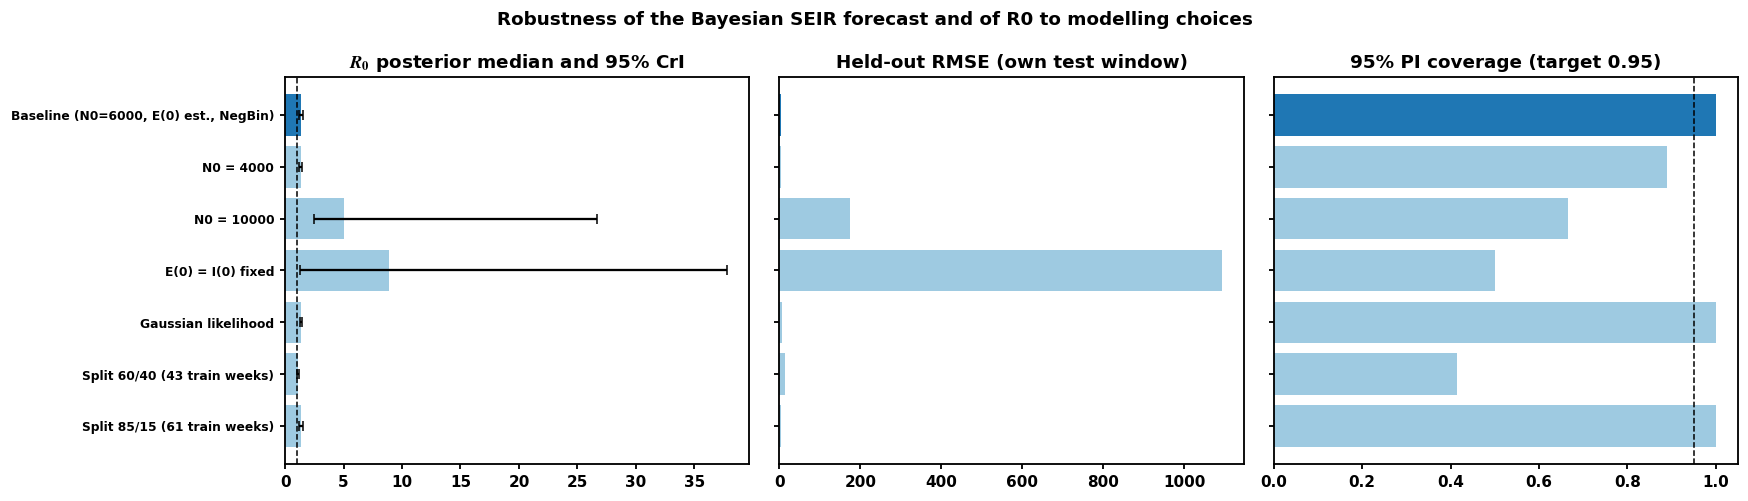

In [ ]:
ROB_ROWS = []
def add_rob(label, n_tr, sc, r0q, rhat, at_bound):
    ROB_ROWS.append(dict(Variant=label, train_weeks=n_tr, RMSE=sc["RMSE"], MAE=sc["MAE"], Coverage=sc["Coverage"], AIW=sc["AIW"], CRPS=sc["CRPS"],
                         R0_lo=r0q[0], R0_median=r0q[1], R0_hi=r0q[2], Rhat=rhat, at_bound=at_bound))

if RUN_STUDIES:
    # baseline = the main pipeline (no re-run)
    add_rob("Baseline (N0=6000, E(0) est., NegBin)", N_TRAIN, score_window(y_test, bayes_point[sl], y_rep[:, sl]),
            np.percentile(R0_post, [2.5, 50, 97.5]), float(diag["split_Rhat"].max()), bool(calib["at_bound"].any()))
    variants = [("N0 = 4000", N_TRAIN, 4000.0, True, "negbin"), ("N0 = 10000", N_TRAIN, 10000.0, True, "negbin"),
                ("E(0) = I(0) fixed", N_TRAIN, N0, False, "negbin"), ("Gaussian likelihood", N_TRAIN, N0, True, "gaussian")]
    variants += [(f"Split {int(round(100*n/N))}/{100-int(round(100*n/N))} ({n} train weeks)", n, N0, True, "negbin") for n in ROBUST_SPLITS]
    for label, n_tr, N0_, est, lik in variants:
        t0_ = time.time()
        try:
            warm = THETA4_MAIN.copy(); warm[0] *= N0 / N0_
            cal = calibrate_g(y[:n_tr], N0_, est, STUDY_STARTS, SEED + n_tr, warm=[warm])
            bay = bayes_g(cal, y, n_tr, N - n_tr, lik, STUDY_CHAINS, STUDY_ITER, STUDY_BURN, STUDY_DRAWS, SEED + n_tr)
            sc = score_window(y[n_tr:], bay["point"][n_tr:], bay["reps"][:, n_tr:])
            add_rob(label, n_tr, sc, np.percentile(bay["R0"], [2.5, 50, 97.5]), bay["rhat"], cal["at_bound"])
            print(f"{label:<42s} done in {time.time()-t0_:.0f}s | RMSE {sc['RMSE']:.2f} cov {sc['Coverage']:.2f} "
                  f"R0 {np.median(bay['R0']):.2f} R-hat {bay['rhat']:.2f} at-bound={cal['at_bound']}")
        except Exception as e:
            print(f"{label}: FAILED ({type(e).__name__}: {e})")

if ROB_ROWS:
    rob_tab = pd.DataFrame(ROB_ROWS).set_index("Variant"); show(rob_tab.round(3)); rob_tab.to_csv("brazil_robustness.csv")
    print("Note: rows with different train/test splits are scored on their own test windows, so their RMSE is not directly comparable.")
    labs = list(rob_tab.index); cols = ["C0"] + ["#9ecae1"] * (len(labs) - 1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    xerr = [rob_tab["R0_median"] - rob_tab["R0_lo"], rob_tab["R0_hi"] - rob_tab["R0_median"]]
    axes[0].barh(range(len(labs)), rob_tab["R0_median"], xerr=xerr, color=cols, capsize=3); axes[0].axvline(1, c="k", ls="--", lw=1)
    axes[0].set_yticks(range(len(labs))); axes[0].set_yticklabels(labs, fontsize=8); axes[0].invert_yaxis(); axes[0].set_title(r"$R_0$ posterior median and 95% CrI")
    for ax, col, ttl in [(axes[1], "RMSE", "Held-out RMSE (own test window)"), (axes[2], "Coverage", "95% PI coverage (target 0.95)")]:
        ax.barh(range(len(labs)), rob_tab[col], color=cols); ax.set_yticks(range(len(labs))); ax.set_yticklabels([""] * len(labs)); ax.invert_yaxis(); ax.set_title(ttl)
    axes[2].axvline(0.95, c="k", ls="--", lw=1)
    fig.suptitle("Robustness of the Bayesian SEIR forecast and of R0 to modelling choices", fontweight="bold")
    savefig("fig15_robustness.png")

## Block 18c — Study D2: sensitivity to the observation model (Table 9, new rows) — with a convergence gate
The main analysis compares weekly counts with the prevalence state, $Y_t \sim I(t)$. Here the mechanistic and Bayesian models are **re-calibrated and re-sampled from scratch** with a weekly-flow observation, $Y_k\sim\mathrm{NegBin}(\rho\int_k^{k+1}\text{flow}\,dt,\phi)$, where the flow is either the **progression** $\sigma E$ (people entering the infectious class; the natural choice here because $E$ acts as an effective delay stage) or the **newly acquired infections** $\lambda S$ (`INC_FLOWS`), with $\rho=1$ and with $\rho$ estimated.
$I(0)$ is **not** set to $Y_1$ (a weekly flow is not a number of infectious people). `INC_I0_MODE = "tied"` sets $I(0)=\sigma E(0)/(\mu+\delta+\gamma+\tau)$; `"estimated"` makes it a parameter. In a full-length test the estimated version mixed very badly ($\hat R$ up to 1.24 and bulk ESS about 14 for $I(0)$), so "tied" is the default.
Chains start from **dispersed** values. A row enters the LaTeX table only if all rank-normalised $\hat R\le1.01$ and bulk/tail ESS $\ge400$; otherwise it is printed but not tabulated and must not be interpreted.

## Block 18d — Figure: MCMC convergence
Trace plots of the four main parameters (near-optimum and dispersed chains) and rank-normalised $\hat R$, bulk ESS and tail ESS for the main analysis and every observation-model run, with pass/fail against $\hat R\le1.01$ and ESS $\ge400$.

In [ ]:
_pre_inc = dict(globals())      # snapshot: this block must not overwrite variables that other cells rely on
# =====================================================================================================
# BLOCK 18c (v2) - Sensitivity to the OBSERVATION MODEL, with a convergence gate
#   Y_k ~ NegBin( rho * m_k , phi ),   m_k = integral_k^{k+1} flow(t) dt,  k = 0..n-1   (counts of week k)
#   INC_FLOW = "progression" : flow = sigma*E                 (people entering the infectious class: onset of infectiousness)
#              "infection"   : flow = lambda(E,I)*S           (newly acquired infections)
#   which one is appropriate depends on what a confirmed case represents. In this model E is an EFFECTIVE delay stage
#   (sigma ~ 0.08/week in the main fit), so a case that is detected at the end of that delay corresponds to "progression";
#   "infection" would assume cases are counted at the moment of infection. Both are run so the manuscript can report either.
#   I(0) is NOT set to Y_1 here (Y_1 is a weekly flow, not a number of infectious people):
#   INC_I0_MODE = "estimated" : I(0) is a parameter (log-uniform on [1e-2, 3e3])
#                 "tied"      : I(0) = sigma*E(0)/(mu+delta+gamma+tau)   (quasi-steady state of the E->I chain; one parameter fewer)
#   Variants are re-calibrated (least squares) and re-sampled (MCMC, dispersed starts) from scratch; nothing from the
#   prevalence-proxy posterior is reused. Rows enter the LaTeX table ONLY if the convergence gate is passed.
# =====================================================================================================
RUN_INCIDENCE = True
THETA4_MAIN   = np.array([b2_m, s_m, tau_m, E0_m])
INC_FLOWS     = ["progression", "infection"]
INC_I0_MODE   = "tied"
INC_STARTS    = 3 * STUDY_STARTS
INC_CHAINS    = 4
INC_ITER, INC_BURN, INC_DRAWS = (1500, 700, 300) if FAST_TEST else (12000, 6000, 2000)
INC_DISP_SD   = 0.3                              # sd (log scale) of the dispersed initial values around the least-squares solution
LOW_RHO, HIGH_RHO = 1e-3, 1.0
I0_LOW, I0_HIGH   = 1e-2, 3e3
RHAT_MAX, ESS_MIN = 1.01, 400                    # screening targets (Vehtari et al., 2021)

def inc_layout(rho_free, i0mode):
    names = ["beta2", "sigma", "tau", "E0"] + (["I0"] if i0mode == "estimated" else []) + (["rho"] if rho_free else [])
    lo = {"beta2": LOW_ALL[0], "sigma": LOW_ALL[1], "tau": LOW_ALL[2], "E0": LOW_ALL[3], "I0": I0_LOW, "rho": LOW_RHO}
    hi = {"beta2": HIGH_ALL[0], "sigma": HIGH_ALL[1], "tau": HIGH_ALL[2], "E0": HIGH_ALL[3], "I0": I0_HIGH, "rho": HIGH_RHO}
    return names, np.log([lo[n] for n in names]), np.log([hi[n] for n in names])

def inc_params(z, names, i0mode):
    v = dict(zip(names, np.exp(z)))
    b2, sg, ta, e0 = v["beta2"], v["sigma"], v["tau"], v["E0"]
    i0 = v["I0"] if i0mode == "estimated" else sg * e0 / (mu + FIXED["delta"] + FIXED["gamma"] + ta)
    return b2, sg, ta, e0, i0, v.get("rho", 1.0)

def sim_weekly_inc(par, N0_, n_out, flow):
    """expected weekly counts rho*(C(k+1)-C(k)), k = 0..n_out-1 with dC/dt = flow; NaN array if the solver fails"""
    b2, sg, ta, e0, i0, rho = par
    if min(e0, i0, rho) <= 0 or e0 + i0 >= N0_: return np.full(n_out, np.nan)
    p = {**FIXED, "N0": float(N0_), "Lambda": mu * N0_, "beta2": b2, "sigma": sg, "tau": ta}
    def rhs(t, X):
        S, E, I, R, Cc = X
        base = list(seir_rhs(t, [S, E, I, R], p))
        dC = sg * E if flow == "progression" else (p["beta1"] * E + (b2 - p["beta3"] * I / (p["k"] + I)) * I) * S
        return base + [dC]
    try:
        sol = solve_ivp(rhs, (0.0, float(n_out)), [N0_ - e0 - i0, e0, i0, 0.0, 0.0], t_eval=np.arange(n_out + 1, dtype=float),
                        method="LSODA", rtol=1e-7, atol=1e-9)
        if (not sol.success) or sol.y.shape[1] != n_out + 1 or not np.all(np.isfinite(sol.y)): raise RuntimeError
        return rho * np.diff(sol.y[4])
    except Exception:
        return np.full(n_out, np.nan)

def calibrate_inc2(y_tr, N0_, flow, i0mode, rho_free, n_starts, seed, warm=()):
    n = len(y_tr); scale = max(float(np.std(y_tr)), 1.0)
    names, lo, hi = inc_layout(rho_free, i0mode); k = len(names)
    def resid(z):
        m = sim_weekly_inc(inc_params(z, names, i0mode), N0_, n, flow)
        return np.full(n, 1e3) if np.any(np.isnan(m)) else (m - y_tr) / scale
    r = np.random.default_rng(seed)
    starts = [np.clip(np.log(np.asarray(w, float)[:k]), lo, hi) for w in warm] + [r.uniform(lo, hi) for _ in range(n_starts)]
    fits = []
    for z0 in starts:
        try: fits.append(least_squares(resid, z0, bounds=(lo, hi), method="trf", max_nfev=150))
        except Exception: pass
    if not fits: raise RuntimeError("calibration failed for all starts")
    fits.sort(key=lambda f: f.cost)
    b = least_squares(resid, fits[0].x, bounds=(lo, hi), method="trf", max_nfev=600, xtol=1e-12, ftol=1e-12, gtol=1e-12)
    edge = 0.01 * (hi - lo)
    return dict(z=b.x, names=names, lo=lo, hi=hi, k=k, cost=b.cost, scale=scale, n=n, i0mode=i0mode, rho_free=rho_free, flow=flow, N0=N0_,
                theta=dict(zip(names, np.exp(b.x))), train_rmse=float(np.sqrt(np.mean((resid(b.x) * scale) ** 2))),
                bound_parameters=[nm for nm, a, c, z_ in zip(names, b.x - lo < edge, hi - b.x < edge, b.x) if a or c])

def mcmc_g2(logpost, z0, lo, hi, n_iter, n_burn, seed):
    """same sampler as mcmc_g (adaptive random-walk Metropolis, adaptation during burn-in only) but also returns the post-burn-in acceptance rate"""
    r = np.random.default_rng(seed); d = len(z0); z, lp = z0.copy(), logpost(z0)
    cov = np.diag(((hi - lo) * 0.01) ** 2); chain = np.empty((n_iter, d)); acc = 0
    for i in range(n_iter):
        if 500 <= i < n_burn and i % 250 == 0:
            cov = (2.38 ** 2 / d) * (np.cov(chain[max(0, i - 2000):i].T) + 1e-10 * np.eye(d))
        prop = r.multivariate_normal(z, cov); lpp = logpost(prop)
        if np.log(r.uniform()) < lpp - lp:
            z, lp = prop, lpp
            if i >= n_burn: acc += 1
        chain[i] = z
    return chain, acc / max(1, n_iter - n_burn)

def bayes_inc2(cal, y_all, n_train, H, n_chains, n_iter, n_burn, n_draws, seed):
    y_tr = y_all[:n_train]; names, i0mode, flow, N0_ = cal["names"], cal["i0mode"], cal["flow"], cal["N0"]; k = cal["k"]
    lo = np.append(cal["lo"], np.log(0.1)); hi = np.append(cal["hi"], np.log(1e3))
    def logpost(z):
        if np.any(z < lo) or np.any(z > hi): return -np.inf
        m = sim_weekly_inc(inc_params(z[:k], names, i0mode), N0_, n_train, flow)
        return -np.inf if np.any(np.isnan(m)) else nb_loglik(y_tr, np.maximum(m, 1e-8), np.exp(z[-1]))
    z_start = np.append(cal["z"], np.log(20.0)); chains_, accs = [], []
    for c in range(n_chains):                                          # DISPERSED starting values (not a tiny ball around the optimum)
        for a_ in range(200):
            z_init = np.clip(z_start + np.random.default_rng(seed + 31 * a_ + c).normal(0, INC_DISP_SD, len(z_start)), lo + 1e-3, hi - 1e-3)
            if np.isfinite(logpost(z_init)): break
        ch, acc = mcmc_g2(logpost, z_init, lo, hi, n_iter, n_burn, seed + 1000 + c); chains_.append(ch); accs.append(acc)
    post = np.array(chains_)[:, n_burn:, :]; labels = names + ["phi"]
    dtab, ok = mcmc_diag(post, labels, lo, hi, accept=accs, rhat_max=RHAT_MAX, ess_min=ESS_MIN)
    flat = np.exp(post.reshape(-1, post.shape[2])); r = np.random.default_rng(seed + 5)
    flat = flat[r.choice(len(flat), size=min(n_draws, len(flat)), replace=False)]
    curves, reps, r0, rhos = [], [], [], []
    for row in flat:
        par = inc_params(np.log(row[:k]), names, i0mode); m = sim_weekly_inc(par, N0_, n_train + H, flow)
        if np.any(np.isnan(m)): continue
        curves.append(m); reps.append(sample_obs(m, row[-1], "negbin", r)); r0.append(R0_g(par[0], par[1], par[2], N0_)); rhos.append(par[5])
    curves, reps = np.array(curves), np.array(reps)
    return dict(curves=curves, reps=reps, point=np.median(curves, 0), R0=np.array(r0), rho=np.array(rhos),
                diag=dtab, ok=ok, chains=post, labels=labels, accept=float(np.mean(accs)), lo=lo, hi=hi)

CONV_RUNS, OBS_ROWS = {}, []
if RUN_INCIDENCE:
    sl_ = slice(N_TRAIN, N)
    sc_A = score_window(y_test, bayes_point[sl_], y_rep[:, sl_])
    OBS_ROWS.append(dict(Observation_model="Prevalence proxy, Y_t ~ I(t) (main analysis)", RMSE=sc_A["RMSE"], R0_lo=np.percentile(R0_post, 2.5),
                         R0_med=np.median(R0_post), R0_hi=np.percentile(R0_post, 97.5), Coverage=sc_A["Coverage"], AIW=sc_A["AIW"], CRPS=sc_A["CRPS"],
                         rho_med=1.0, train_RMSE=metrics(y_train, y_mech_all[:N_TRAIN])["RMSE"],
                         Rhat_rank=float(MAIN_DIAG["Rhat_rank"].max()) if "MAIN_DIAG" in globals() else np.nan,
                         ESS_bulk_min=float(MAIN_DIAG["ESS_bulk"].min()) if "MAIN_DIAG" in globals() else np.nan,
                         ESS_tail_min=float(MAIN_DIAG["ESS_tail"].min()) if "MAIN_DIAG" in globals() else np.nan,
                         Converged=bool(MAIN_OK) if "MAIN_OK" in globals() else None, At_bound=""))
    for flow in INC_FLOWS:
        for rho_free in (False, True):
            label = f"Weekly {'new infections' if flow == 'infection' else 'progression into I'}, rho {'estimated' if rho_free else '= 1'}"
            t0_ = time.time()
            try:
                warm = [np.array([THETA4_MAIN[0], THETA4_MAIN[1], THETA4_MAIN[2], THETA4_MAIN[3], max(float(y[0]), 1.0), 0.5])]
                warm = [w[:inc_layout(rho_free, INC_I0_MODE)[1].size] if not rho_free else (w if INC_I0_MODE == "estimated" else np.delete(w, 4)) for w in warm]
                cal_i = calibrate_inc2(y[:N_TRAIN], N0, flow, INC_I0_MODE, rho_free, INC_STARTS, SEED + 77, warm=warm)
                bay_i = bayes_inc2(cal_i, y, N_TRAIN, N - N_TRAIN, INC_CHAINS, INC_ITER, INC_BURN, INC_DRAWS, SEED + 77)
                sc = score_window(y_test, bay_i["point"][N_TRAIN:], bay_i["reps"][:, N_TRAIN:]); dt_ = bay_i["diag"]
                CONV_RUNS[label] = dict(chains=bay_i["chains"], labels=bay_i["labels"], diag=dt_, ok=bay_i["ok"], accept=bay_i["accept"], lo=bay_i["lo"], hi=bay_i["hi"])
                OBS_ROWS.append(dict(Observation_model=label, RMSE=sc["RMSE"], R0_lo=np.percentile(bay_i["R0"], 2.5), R0_med=np.median(bay_i["R0"]),
                                     R0_hi=np.percentile(bay_i["R0"], 97.5), Coverage=sc["Coverage"], AIW=sc["AIW"], CRPS=sc["CRPS"], rho_med=float(np.median(bay_i["rho"])),
                                     train_RMSE=cal_i["train_rmse"], Rhat_rank=float(dt_["Rhat_rank"].max()), ESS_bulk_min=float(dt_["ESS_bulk"].min()),
                                     ESS_tail_min=float(dt_["ESS_tail"].min()), Converged=bay_i["ok"], At_bound=",".join(cal_i["bound_parameters"])))
                print(f"\n{label}  [I(0) {INC_I0_MODE}]  done in {time.time()-t0_:.0f}s | LS train RMSE {cal_i['train_rmse']:.2f} | LS parameters at a bound: {cal_i['bound_parameters'] or 'none'}"
                      f" | acceptance {bay_i['accept']:.2f} | CONVERGED: {bay_i['ok']}")
                show(dt_.round(3))
            except Exception as e:
                print(f"{label}: FAILED ({type(e).__name__}: {e})")
if OBS_ROWS:
    obs_tab = pd.DataFrame(OBS_ROWS).set_index("Observation_model"); show(obs_tab.round(3)); obs_tab.to_csv("brazil_observation_model_sensitivity.csv")
    os.makedirs("tex_snippets", exist_ok=True)
    def _f(x, d=2): return "---" if not np.isfinite(x) else f"{x:.{d}f}"
    is_main = lambda n: n.startswith("Prevalence proxy")
    keep = [(n, r) for n, r in obs_tab.iterrows() if is_main(n) or r["Converged"] is not False]   # gate: sensitivity rows that fail the diagnostics are NOT tabulated (the main row always stays)
    dropped = [n for n, r in obs_tab.iterrows() if (not is_main(n)) and r["Converged"] is False]
    rows_tex = [rf"{n.replace('_', r'\_').replace('%', r'\%')} & {_f(r['RMSE'])} & {_f(r['R0_med'])} [{_f(r['R0_lo'])}, {_f(r['R0_hi'])}] & {_f(r['Coverage'])} & {_f(r['AIW'])} \\"
                for n, r in keep]
    body = [r"\begin{tabular}{lcccc}", r"\toprule", r"Observation model & RMSE & $R_0$ median [95\% CrI] & Coverage & AIW \\", r"\midrule"] + rows_tex + [r"\bottomrule", r"\end{tabular}"]
    open("tex_snippets/tab_obsmodel.tex", "w").write("\n".join(body) + "\n")
    if dropped:
        print(f"\nNOT tabulated (convergence gate Rhat_rank <= {RHAT_MAX}, bulk and tail ESS >= {ESS_MIN} failed): {dropped}")
        print("Do not interpret R0 or the forecast scores of these rows. Investigate the posterior geometry (trace plots in fig18) before lengthening the chains.")
    print("written tex_snippets/tab_obsmodel.tex (converged rows only)")

# restore any pre-existing global that this block overwrote (loop variables such as tab, rows, d, k ...); the block's own results stay
for _k_ in list(globals()):
    if _k_ in _pre_inc and _k_ != "_pre_inc" and globals()[_k_] is not _pre_inc[_k_] and _k_ not in ("THETA4_MAIN",):
        globals()[_k_] = _pre_inc[_k_]



Weekly progression into I, rho = 1  [I(0) tied]  done in 693s | LS train RMSE 34.94 | LS parameters at a bound: ['tau'] | acceptance 0.08 | CONVERGED: False
       Rhat_rank  Rhat_classic  ESS_bulk  ESS_tail  near_bound_%
beta2      1.363         1.348     9.132    46.885          0.00
sigma      1.252         1.266    12.549    51.764          0.25
tau        1.231         1.224    13.568    75.257          0.00
E0         1.101         1.129    37.640    48.805          0.00
phi        1.076         1.075   101.551   212.179          0.00

Weekly progression into I, rho estimated  [I(0) tied]  done in 776s | LS train RMSE 18.60 | LS parameters at a bound: none | acceptance 0.11 | CONVERGED: False
       Rhat_rank  Rhat_classic  ESS_bulk  ESS_tail  near_bound_%
beta2      1.024         1.025   202.138   208.879         0.000
sigma      1.026         1.028   336.160   271.283         0.000
tau        1.016         1.015   326.045   339.234         0.000
E0         1.007         1.007 

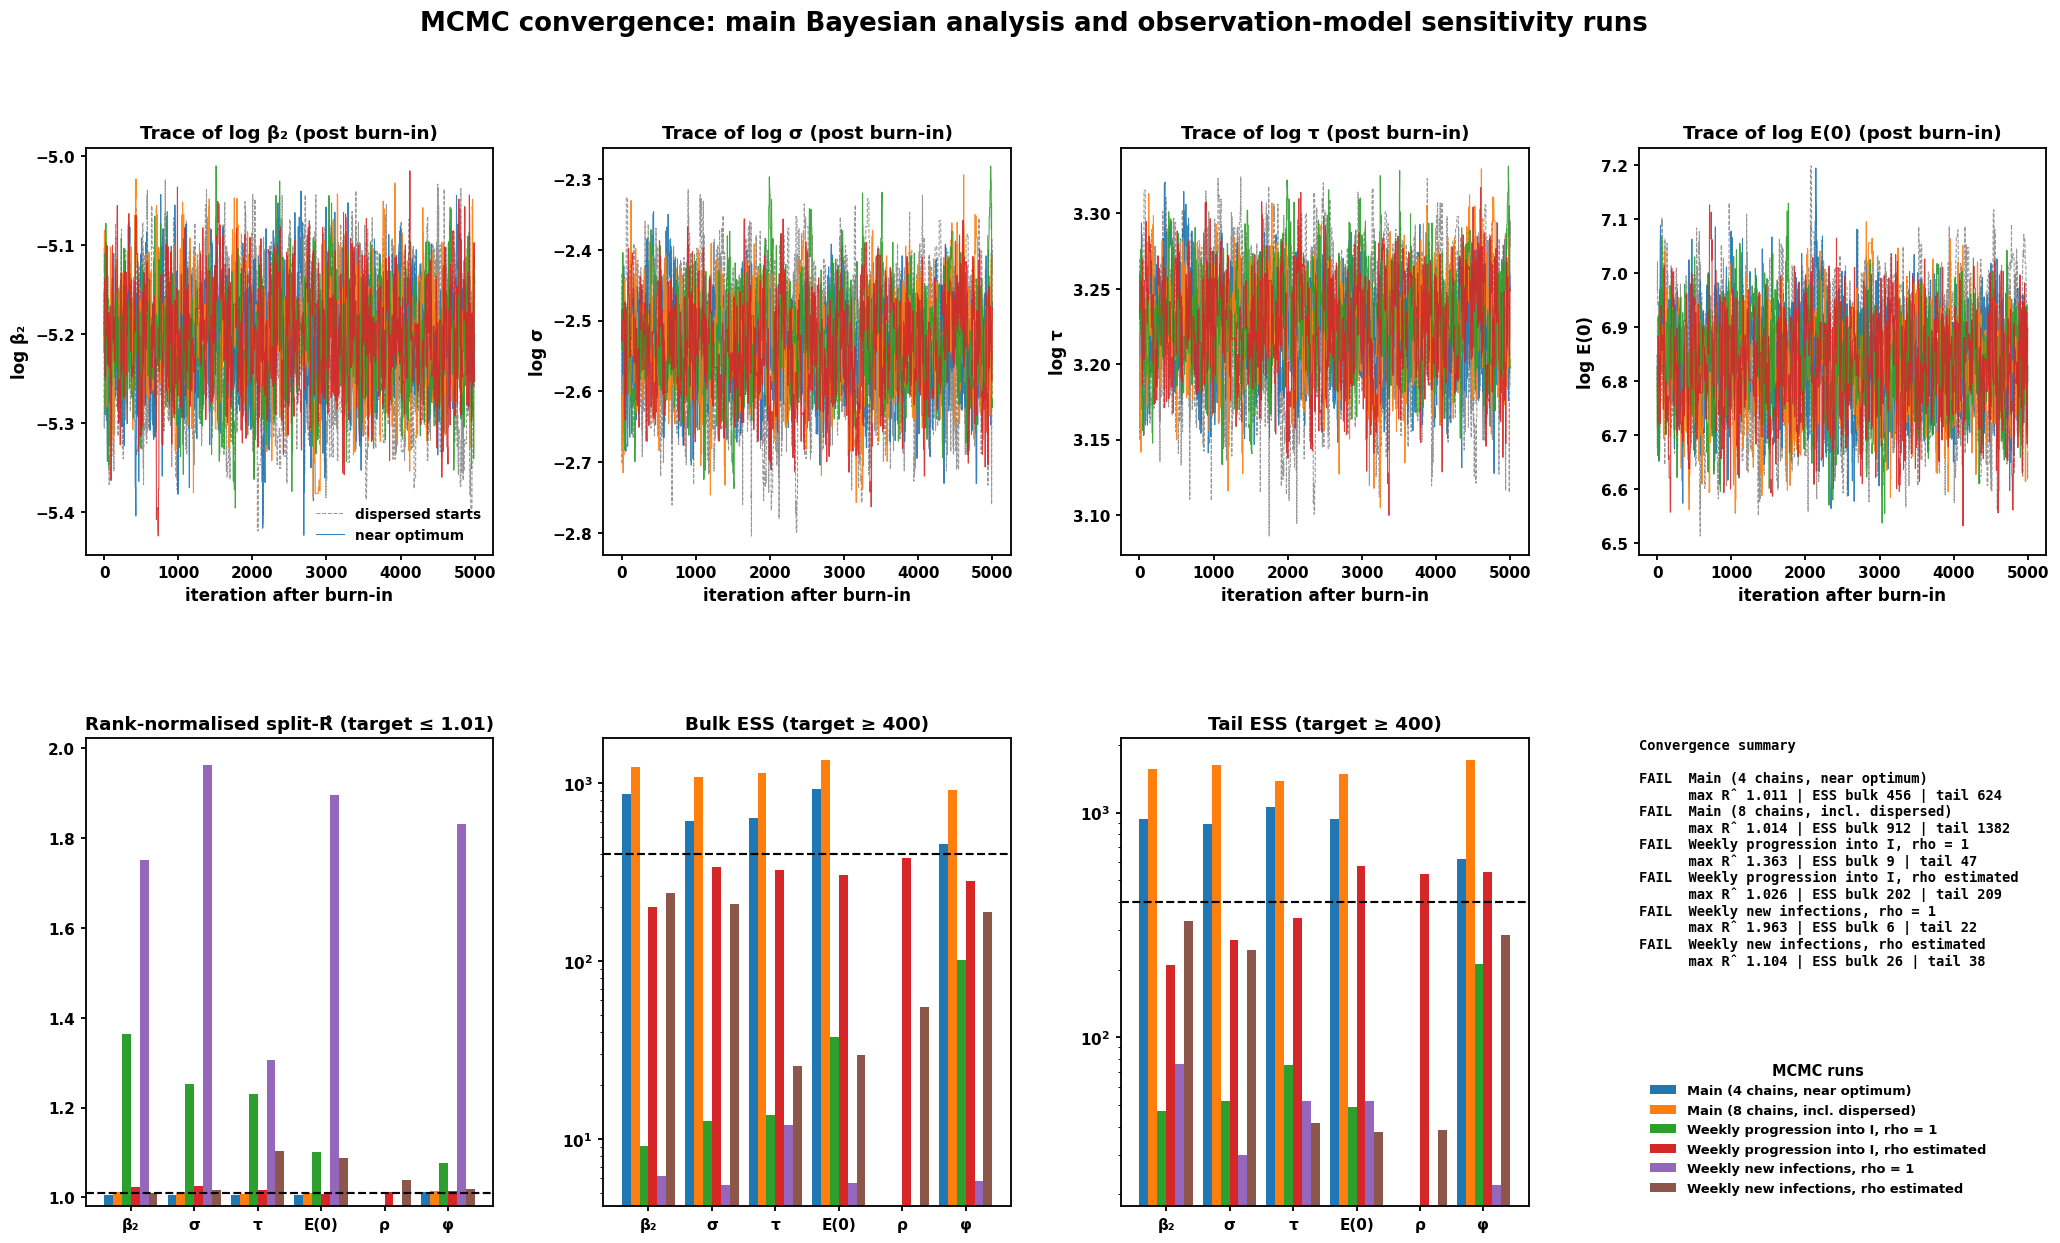

In [ ]:
_pre_cf = dict(globals())
# =====================================================================================================
# BLOCK 18d - FIGURE: MCMC convergence (fig18_mcmc_convergence.png)
#   top row    : trace plots of the four main parameters, 4 chains near the optimum (solid) and 4 dispersed-start chains (dashed grey)
#   bottom row : rank-normalised split-Rhat, bulk ESS and tail ESS for every parameter and every Bayesian run, plus a pass/fail summary
# =====================================================================================================
_PN = {"beta2": "β₂", "sigma": "σ", "tau": "τ", "E0": "E(0)", "I0": "I(0)", "rho": "ρ", "phi": "φ"}
_groups = {"Main (4 chains, near optimum)": MAIN_DIAG}
if MAIN_DIAG8 is not None: _groups["Main (8 chains, incl. dispersed)"] = MAIN_DIAG8
for _lab, _run in CONV_RUNS.items(): _groups[_lab] = _run["diag"]
_pars = [p for p in ["beta2", "sigma", "tau", "E0", "I0", "rho", "phi"] if any(p in g.index for g in _groups.values())]
fig = plt.figure(figsize=(23, 12.5)); gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.15], hspace=0.42, wspace=0.27)
for j, nm in enumerate(["beta2", "sigma", "tau", "E0"]):
    ax = fig.add_subplot(gs[0, j]); jj = LABELS.index(nm)
    if DISP_CHAINS is not None:
        for c in range(DISP_CHAINS.shape[0]): ax.plot(DISP_CHAINS[c, :, jj], lw=0.7, color="0.55", ls="--", alpha=0.9, label="dispersed starts" if c == 0 else None)
    for c in range(chains.shape[0]): ax.plot(chains[c, :, jj], lw=0.7, color=f"C{c}", alpha=0.9, label="near optimum" if c == 0 else None)
    ax.set_title(f"Trace of log {_PN[nm]} (post burn-in)"); ax.set_xlabel("iteration after burn-in"); ax.set_ylabel(f"log {_PN[nm]}")
    if j == 0: ax.legend(frameon=False, fontsize=9, loc="best")
_cols = plt.cm.tab10(np.linspace(0, 1, 10)); xs = np.arange(len(_pars)); w = 0.84 / len(_groups)
for pi, (col, ttl, thr, logy) in enumerate([("Rhat_rank", "Rank-normalised split-R̂ (target ≤ 1.01)", 1.01, False),
                                            ("ESS_bulk", "Bulk ESS (target ≥ 400)", 400, True), ("ESS_tail", "Tail ESS (target ≥ 400)", 400, True)]):
    ax = fig.add_subplot(gs[1, pi])
    for gi, (lab, dtab) in enumerate(_groups.items()):
        vals = [dtab[col].get(p, np.nan) for p in _pars]
        ax.bar(xs + (gi - (len(_groups) - 1) / 2) * w, vals, w, color=_cols[gi], label=lab)
    ax.axhline(thr, color="k", ls="--", lw=1.4)
    if logy: ax.set_yscale("log")
    else: ax.set_ylim(0.98, max(1.1, np.nanmax([g["Rhat_rank"].max() for g in _groups.values()]) * 1.03))
    ax.set_xticks(xs); ax.set_xticklabels([_PN[p] for p in _pars]); ax.set_title(ttl)
    if pi == 0: _h, _l = ax.get_legend_handles_labels()
ax = fig.add_subplot(gs[1, 3]); ax.axis("off")
_lines = ["Convergence summary", ""]
for lab, dtab in _groups.items():
    _ok = bool((dtab["Rhat_rank"] <= 1.01).all() and (dtab["ESS_bulk"] >= 400).all() and (dtab["ESS_tail"] >= 400).all())
    _lines += [f"{'PASS' if _ok else 'FAIL'}  {lab}", f"      max R̂ {dtab['Rhat_rank'].max():.3f} | ESS bulk {dtab['ESS_bulk'].min():.0f} | tail {dtab['ESS_tail'].min():.0f}"]
ax.text(0.0, 1.0, "\n".join(_lines), va="top", ha="left", fontsize=9, family="DejaVu Sans Mono", transform=ax.transAxes)
ax.legend(_h, _l, loc="lower left", frameon=False, fontsize=8.5, title="MCMC runs", title_fontsize=9.5)
fig.suptitle("MCMC convergence: main Bayesian analysis and observation-model sensitivity runs", fontsize=17, fontweight="bold")
savefig("fig18_mcmc_convergence.png")
for _k_ in list(globals()):
    if _k_ in _pre_cf and _k_ != "_pre_cf" and globals()[_k_] is not _pre_cf[_k_]:
        globals()[_k_] = _pre_cf[_k_]


## Block 18b — Table rows for the study tables
Writes ready-to-paste `tabular` rows for the new tables.

In [ ]:
SNIP = "tex_snippets"; os.makedirs(SNIP, exist_ok=True)
STUDY_FIGS = ["fig10_framework_matrix.png", "fig11_metric_comparison.png", "fig12_uq_calibration.png",
              "fig13_physics_weight.png", "fig14_rolling_origin.png", "fig15_robustness.png",
              "fig16_rolling_by_horizon.png", "fig17_rolling_by_phase.png", "fig18_mcmc_convergence.png"]
def sci(x, d=2):
    m, e = f"{x:.{d}e}".split("e"); return rf"{m}\times10^{{{int(e)}}}"
def f2(x, d=2): return "---" if (x is None or not np.isfinite(x)) else f"{x:.{d}f}"
def tx(s): return str(s).replace("_", r"\_").replace("%", r"\%")
def put(name, rows): open(f"{SNIP}/{name}", "w").write("\n".join(rows) + "\n")
def put_tab(name, colspec, header, rows, small=False):
    """Complete tabular environment (header + rows) so the .tex can simply \\input{} it."""
    body = [r"\begin{tabular}{" + colspec + "}", r"\toprule", header + r" \\", r"\midrule"] + rows + [r"\bottomrule", r"\end{tabular}"]
    open(f"{SNIP}/{name}", "w").write("\n".join(body) + "\n")

put("tab_capability_rows.tex", CAP_TEX)
if "cmp_tab" in globals():
    put("tab_compare_rows.tex", [rf"{tx(n)} & {f2(r['RMSE'])} & {f2(r['MAE'])} & {f2(r['sMAPE_%'])} & {f2(r['Coverage'])} & {f2(r['AIW'])} & {f2(r['IS'])} & {f2(r['CRPS'])} \\"
                                 for n, r in cmp_tab.iterrows()])
if "contrib_tab" in globals():
    put("tab_contrib_rows.tex", [rf"{tx(n)} & {f2(r['dRMSE'])} & {f2(r['dMAE'])} & {f2(r['dCoverage'])} & {f2(r['dIS'])} & {f2(r['dCRPS'])} \\"
                                 for n, r in contrib_tab.iterrows()])
if "ro_macro" in globals():
    put("tab_rolling_rows.tex", [rf"{tx(n)} & {f2(r['RMSE'])} & {f2(r['MAE'])} & {f2(r['Coverage'])} & {f2(r['AIW'])} & {f2(r['IS'])} & {f2(r['CRPS'])} \\"
                                 for n, r in ro_macro.iterrows()])
if "rob_tab" in globals():
    put("tab_robust_rows.tex", [rf"{tx(n)} & {f2(r['RMSE'])} & {f2(r['R0_median'])} [{f2(r['R0_lo'])}, {f2(r['R0_hi'])}] & {f2(r['Coverage'])} & {f2(r['AIW'])} \\"
                                for n, r in rob_tab.iterrows()])
if "phys_tab" in globals():
    put("tab_physics_rows.tex", [rf"{n.replace('w_p', r'$w_p$')} & {f2(r['train RMSE'])} & {f2(r['test RMSE'])} & {f2(r['test MAE'])} & ${sci(r['final physics residual'], 2)}$ \\"
                                 for n, r in phys_tab.iterrows()])
def rows_of(fn): return open(f"{SNIP}/{fn}").read().strip().split("\n")
H = {"tab_capability_rows.tex": ("lcccc", r"Framework & Mechanism & Physics constraint & Bayesian UQ & Out-of-sample"),
     "tab_compare_rows.tex":    ("lccccccc", r"Framework & RMSE & MAE & sMAPE (\%) & Coverage & AIW & IS & CRPS"),
     "tab_contrib_rows.tex":    ("lccccc", r"Component added & $\Delta$RMSE & $\Delta$MAE & $\Delta$Coverage & $\Delta$IS & $\Delta$CRPS"),
     "tab_rolling_rows.tex":    ("lcccccc", r"Framework & RMSE & MAE & Coverage & AIW & IS & CRPS"),
     "tab_robust_rows.tex":     ("lcccc", r"Variant & RMSE & $R_0$ median [95\% CrI] & Coverage & AIW"),
     "tab_physics_rows.tex":    ("lcccc", r"Physics weight & Train RMSE & Test RMSE & Test MAE & Final physics residual")}
for fn, (cs, hd) in H.items():
    if os.path.exists(f"{SNIP}/{fn}"): put_tab(fn.replace("_rows", ""), cs, hd, rows_of(fn))
print("study table rows written to", SNIP, "->", sorted(f for f in os.listdir(SNIP) if f.startswith("tab_")))

study table rows written to tex_snippets -> ['tab_capability.tex', 'tab_capability_rows.tex', 'tab_compare.tex', 'tab_compare_rows.tex', 'tab_contrib.tex', 'tab_contrib_rows.tex', 'tab_obsmodel.tex', 'tab_physics.tex', 'tab_physics_rows.tex', 'tab_robust.tex', 'tab_robust_rows.tex', 'tab_rolling.tex', 'tab_rolling_horizon.tex', 'tab_rolling_phase.tex', 'tab_rolling_rows.tex']


## Block 19 — Export everything the LaTeX needs (figures, table rows, numbers for the text)

* Checks that **all nine figure files used by the manuscript exist** under their exact names.
* Writes ready-to-paste `tabular` rows to `tex_snippets/` (replace the table bodies in `main_revised.tex`).
* Writes `tex_snippets/numbers_for_text.txt` (abstract / results sentences) and bundles everything into `figures_for_tex.zip`.

In [ ]:
import zipfile
SNIP = "tex_snippets"; os.makedirs(SNIP, exist_ok=True)
REQUIRED_FIGS = ["fig01_data_split.png", "fig02_mech_fit_forecast.png", "fig04_mech_residuals.png",
                 "fig05_pinn_training.png", "fig06_posteriors.png", "fig07_beta2_tau.png",
                 "fig08_bayes_predictive.png", "fig09_final_comparison.png", "fig_pinn_vs_mech.png"]
if RUN_STUDIES and "STUDY_FIGS" in globals():
    REQUIRED_FIGS = REQUIRED_FIGS + [f for f in STUDY_FIGS if f != "fig13_physics_weight.png" or HAVE_TORCH]
PRETTY = {"beta2": r"\beta_2", "sigma": r"\sigma", "tau": r"\tau", "E0": r"E(0)", "phi": r"\phi", "R0": r"R_0"}

def sci(x, d=2):
    m, e = f"{x:.{d}e}".split("e"); return rf"{m}\times10^{{{int(e)}}}"
def fmt(x, d=3):
    if x != 0 and (abs(x) < 1e-2 or abs(x) >= 1e4): body = sci(x, d - 1)
    elif abs(x) >= 100: body = f"{x:.0f}"
    else: body = f"{x:.{d}g}"
    return "$" + body + "$"
def fmt_bound(v):
    if 1 <= v < 1000: return f"{v:g}"
    m, e = f"{v:.0e}".split("e"); m, e = int(m), int(e)
    return f"10^{{{e}}}" if m == 1 else rf"{m}\times10^{{{e}}}"

# --- Table: training-only calibration (point estimates) and bounds
rows = [rf"${PRETTY[n]}$ & {fmt(THETA_MECH[i])} & $[{fmt_bound(LOW[i])},{fmt_bound(HIGH[i])}]$ \\" for i, n in enumerate(PNAMES)]
open(f"{SNIP}/tab_calib_rows.tex", "w").write("\n".join(rows) + "\n")

# --- Table: MCMC diagnostics
rows = [rf"${PRETTY[n]}$ & {diag.loc[n, 'split_Rhat']:.3f} & {diag.loc[n, 'ESS']:.0f} \\" for n in LABELS]
open(f"{SNIP}/tab_mcmc_rows.tex", "w").write("\n".join(rows) + "\n")

# --- Table: posterior summaries
rows = [rf"${PRETTY[n]}$ & {fmt(tab.loc[n, 'median'])} & {fmt(tab.loc[n, '2.5%'])} & {fmt(tab.loc[n, '97.5%'])} \\" for n in LABELS + ["R0"]]
open(f"{SNIP}/tab_post_rows.tex", "w").write("\n".join(rows) + "\n")

# --- Table: final out-of-sample comparison (row order = manuscript)
TEXNAME = [("Constant-mean baseline", "Constant-mean baseline"), ("Mechanistic SEIR", "Mechanistic SEIR"),
           ("Standard PINN", "Standard PINN"), ("Bayesian SEIR (posterior median)", "Bayesian SEIR (posterior median)"),
           ("Bayesian-uncertainty PINN ensemble", "Bayesian PINN ensemble")]
rows = []
for key, label in TEXNAME:
    if key not in final_tab.index:
        rows.append(rf"{label} & \todo{{}} & \todo{{}} & \todo{{}} & --- & --- \\"); continue
    r_ = final_tab.loc[key]
    cv = r_["95%PI coverage"] if "95%PI coverage" in r_.index else np.nan
    aw = r_["AIW"] if "AIW" in r_.index else np.nan
    cov = f"{cv:.2f}" if np.isfinite(cv) else "---"
    aiw = f"{aw:.2f}" if np.isfinite(aw) else "---"
    rows.append(rf"{label} & {r_['RMSE']:.2f} & {r_['MAE']:.2f} & {r_['sMAPE_%']:.2f} & {cov} & {aiw} \\")
open(f"{SNIP}/tab_final_rows.tex", "w").write("\n".join(rows) + "\n")

# --- numbers for the abstract / results text
lines = [
  f"R0 posterior median {tab.loc['R0','median']:.2f}, 95% CrI [{tab.loc['R0','2.5%']:.2f}, {tab.loc['R0','97.5%']:.2f}];  P(R0>1|D_train) = {(R0_post > 1).mean():.3f}",
  f"Training-only point-estimate R0 = {R0_fn(b2_m, s_m, tau_m):.3f}",
  f"Mechanistic SEIR: train RMSE {m_tr['RMSE']:.1f}, held-out RMSE {m_te['RMSE']:.1f};  constant-mean baseline: train {base_tr['RMSE']:.1f}, held-out {base_te['RMSE']:.1f}",
  f"MCMC: max split-Rhat {diag['split_Rhat'].max():.3f}, ESS range {diag['ESS'].min():.0f}-{diag['ESS'].max():.0f}",
]
if "Standard PINN" in FORECASTS:
    pt = FORECASTS["Standard PINN"]["point"]
    lines.append("Standard PINN: train RMSE %.1f, held-out RMSE %.1f" % (metrics(y_train, pt[:N_TRAIN])["RMSE"], metrics(y_test, pt[N_TRAIN:])["RMSE"]))
open(f"{SNIP}/numbers_for_text.txt", "w").write("\n".join(lines) + "\n")
print("\n".join(lines))

# --- check figures + bundle
missing = [f for f in REQUIRED_FIGS if not os.path.exists(os.path.join(FIG_DIR, f))]
print("\nFigure check:")
for f in REQUIRED_FIGS: print("  ", "OK     " if f not in missing else "MISSING", f)
if missing: print("*** Missing figures:", missing)
with zipfile.ZipFile("figures_for_tex.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in REQUIRED_FIGS:
        if f not in missing: z.write(os.path.join(FIG_DIR, f), f)
    for f in sorted(os.listdir(SNIP)): z.write(os.path.join(SNIP, f), "tex_snippets/" + f)
print("\nWrote figures_for_tex.zip (9 PNGs + tex_snippets/). Put the PNGs next to main_revised.tex (or in figures_brazil_full/).")
try:                                   # Colab convenience
    from google.colab import files; files.download("figures_for_tex.zip")
except Exception:
    pass

R0 posterior median 1.38, 95% CrI [1.20, 1.58];  P(R0>1|D_train) = 1.000
Training-only point-estimate R0 = 1.501
Mechanistic SEIR: train RMSE 19.8, held-out RMSE 4.5;  constant-mean baseline: train 112.5, held-out 78.7
MCMC: max split-Rhat 1.011, ESS range 673-935
Standard PINN: train RMSE 13.5, held-out RMSE 4.8

Figure check:
   OK      fig01_data_split.png
   OK      fig02_mech_fit_forecast.png
   OK      fig04_mech_residuals.png
   OK      fig05_pinn_training.png
   OK      fig06_posteriors.png
   OK      fig07_beta2_tau.png
   OK      fig08_bayes_predictive.png
   OK      fig09_final_comparison.png
   OK      fig_pinn_vs_mech.png
   OK      fig10_framework_matrix.png
   OK      fig11_metric_comparison.png
   OK      fig12_uq_calibration.png
   OK      fig13_physics_weight.png
   OK      fig14_rolling_origin.png
   OK      fig15_robustness.png
   OK      fig16_rolling_by_horizon.png
   OK      fig17_rolling_by_phase.png
   OK      fig18_mcmc_convergence.png

Wrote figures_for_tex.z

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes for the manuscript

* **Leakage check:** weeks 55–72 enter only the *scoring* in Block 12. Optimiser starts are random, priors are data-independent bounds, collocation points carry no data.
* **Do not mix with the old full-data results.** The values $\beta_2=1.4479\times10^{-4},\sigma=0.159,\tau=0.545$ and their t-based confidence intervals come from fitting all 72 weeks and cannot be reported as the output of this forecasting experiment.
* **Sensitivity analyses still needed:** (i) $N_0$ (6,000 vs 10,000 vs larger) — $\beta_2$ and $N_0$ are close to confounded; (ii) $E(0)$ treatment (fixed vs estimated); (iii) reporting scale $\rho\neq1$; (iv) Gaussian vs Negative-Binomial likelihood.
* **Interpretation of coverage:** report coverage together with AIW; a wide interval can reach 95% coverage trivially.
* With only 18 test points, coverage has a large binomial standard error (about $\pm0.05$ even if the interval is perfectly calibrated).